In [ ]:
from google.colab import drive

drive.mount('/content/drive')

print("✅ Google Drive connected!")

Mounted at /content/drive
✅ Google Drive connected!


In [ ]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator1`
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow Version:", tf.__version__)

In [ ]:
dataset_path = '/content/drive/MyDrive/Fruit Freshness Project/Freshness44/Freshness44'

print("Dataset exists:", os.path.exists(dataset_path))

In [ ]:
classes = sorted([
    folder for folder in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, folder))
])

print("Total Classes:", len(classes))

for i, c in enumerate(classes, 1):
    print(i, c)

In [ ]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

print("Image Size:", IMG_SIZE)
print("Batch Size:", BATCH_SIZE)

In [ ]:
datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True
)

In [ ]:
train_data = datagen.flow_from_directory(
    dataset_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    shuffle=True,
    seed=42
)

Found 31051 images belonging to 30 classes.


In [ ]:
validation_data = datagen.flow_from_directory(
    dataset_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    shuffle=False,
    seed=42
)

Found 7750 images belonging to 30 classes.


In [ ]:

model_path = '/content/drive/MyDrive/Fruit Freshness Project/fruit_freshness_cnn.keras'

if os.path.exists(model_path):
    model = tf.keras.models.load_model(model_path)
    print("✅ Existing trained model loaded successfully!")
else:
    print("⚠️ Trained model not found.")
    print("First time training is required.")

⚠️ Trained model not found.
First time training is required.


In [ ]:
model = models.Sequential([

    layers.Conv2D(32, (3,3), activation='relu',
                  input_shape=(128,128,3)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(128, (3,3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(256, (3,3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2,2)),

    layers.Flatten(),

    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(30, activation='softmax')
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 126, 126, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 61, 61, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 12, 12, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     2,359,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 30)             │         7,710 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,757,598 (10.52 MB)

 Trainable params: 2,756,638 (10.52 MB)

 Non-trainable params: 960 (3.75 KB)

In [ ]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

checkpoint_path = '/content/drive/MyDrive/Fruit Freshness Project/fruit_freshness_checkpoint.keras'

checkpoint = ModelCheckpoint(
    checkpoint_path,
    monitor='val_accuracy',
    save_best_only=True,
    mode='max',
    verbose=1
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

In [ ]:
history = model.fit(
    train_data,
    validation_data=validation_data,
    epochs=10,
    callbacks=[checkpoint, early_stopping]
)

In [ ]:
import tensorflow as tf
import os

checkpoint_path = '/content/drive/MyDrive/Fruit Freshness Project/fruit_freshness_checkpoint.keras'

print("Checkpoint exists:", os.path.exists(checkpoint_path))

best_model = tf.keras.models.load_model(checkpoint_path)

print("✅ Best model loaded successfully!")

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

dataset_path = '/content/drive/MyDrive/Fruit Freshness Project/Freshness44/Freshness44'

IMG_SIZE = (128, 128)
BATCH_SIZE = 32

datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

validation_data = datagen.flow_from_directory(
    dataset_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    shuffle=False,
    seed=42
)

In [ ]:
val_loss, val_accuracy = best_model.evaluate(validation_data)

print("================================")
print("BEST MODEL RESULTS")
print("================================")
print("Validation Loss:", round(val_loss, 4))
print("Validation Accuracy:", round(val_accuracy, 4))
print("Validation Accuracy (%):", round(val_accuracy * 100, 2))

In [ ]:
import numpy as np

In [ ]:
import numpy as np
from sklearn.metrics import classification_report

validation_data.reset()

predictions = best_model.predict(validation_data)

y_pred = np.argmax(predictions, axis=1)
y_true = validation_data.classes

class_names = list(validation_data.class_indices.keys())

report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
)

print(report)

In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

In [ ]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, Model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2

from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
dataset_path = '/content/drive/MyDrive/Fruit Freshness Project/Freshness44/Freshness44'

print("Dataset exists:", os.path.exists(dataset_path))

In [ ]:
class_names = sorted([
    folder for folder in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, folder))
])

print("Total Classes:", len(class_names))

for i, name in enumerate(class_names):
    print(i, name)

In [ ]:
IMG_SIZE = (160, 160)
BATCH_SIZE = 64
NUM_CLASSES = len(class_names)

print("Image Size:", IMG_SIZE)
print("Batch Size:", BATCH_SIZE)
print("Number of Classes:", NUM_CLASSES)

In [ ]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,
    rotation_range=20,
    width_shift_range=0.15,
    height_shift_range=0.15,
    zoom_range=0.15,
    horizontal_flip=True
)

train_data = train_datagen.flow_from_directory(
    dataset_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    classes=class_names,
    subset='training',
    shuffle=True,
    seed=42
)

print("Training images:", train_data.samples)

In [ ]:
val_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

validation_data = val_datagen.flow_from_directory(
    dataset_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    classes=class_names,
    subset='validation',
    shuffle=False,
    seed=42
)

print("Validation images:", validation_data.samples)

In [ ]:
class_weights_array = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(NUM_CLASSES),
    y=train_data.classes
)

class_weights = {
    i: weight
    for i, weight in enumerate(class_weights_array)
}

for i, name in enumerate(class_names):
    print(f"{name}: {class_weights[i]:.4f}")

In [ ]:
base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(160, 160, 3)
)

base_model.trainable = False

print("✅ MobileNetV2 loaded")
print("Base model trainable:", base_model.trainable)

In [ ]:
inputs = layers.Input(shape=(160, 160, 3))

x = base_model(inputs, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dense(256, activation='relu')(x)

x = layers.BatchNormalization()(x)

x = layers.Dropout(0.5)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation='softmax'
)(x)

mobilenet_model = Model(
    inputs,
    outputs
)

mobilenet_model.summary()

In [ ]:
mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("✅ Model compiled")

In [ ]:
checkpoint_path = '/content/drive/MyDrive/Fruit Freshness Project/mobilenetv2_best.keras'

checkpoint = ModelCheckpoint(
    checkpoint_path,
    monitor='val_accuracy',
    mode='max',
    save_best_only=True,
    verbose=1
)

In [ ]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True,
    verbose=1
)

In [ ]:
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.3,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

In [ ]:
BATCH_SIZE = 128

train_data = train_datagen.flow_from_directory(
    dataset_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    classes=class_names,
    subset='training',
    shuffle=True,
    seed=42
)

validation_data = val_datagen.flow_from_directory(
    dataset_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    classes=class_names,
    subset='validation',
    shuffle=False,
    seed=42
)

print("Training images:", train_data.samples)
print("Validation images:", validation_data.samples)

In [ ]:
import shutil
import os

source_path = '/content/drive/MyDrive/Fruit Freshness Project/Freshness44/Freshness44'
local_dataset_path = '/content/Freshness44'

if not os.path.exists(local_dataset_path):
    print("Copying dataset to Colab local storage...")
    shutil.copytree(source_path, local_dataset_path)
    print("✅ Dataset copied successfully!")
else:
    print("✅ Local dataset already exists!")

print("Local dataset exists:", os.path.exists(local_dataset_path))

In [ ]:
dataset_path = '/content/Freshness44'

print("Dataset exists:", os.path.exists(dataset_path))

In [ ]:
BATCH_SIZE = 64

train_data = train_datagen.flow_from_directory(
    dataset_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    classes=class_names,
    subset='training',
    shuffle=True,
    seed=42
)

print("Training images:", train_data.samples)

In [ ]:
validation_data = val_datagen.flow_from_directory(
    dataset_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    classes=class_names,
    subset='validation',
    shuffle=False,
    seed=42
)

print("Validation images:", validation_data.samples)

In [ ]:
class_weights_array = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(NUM_CLASSES),
    y=train_data.classes
)

class_weights = {
    i: weight
    for i, weight in enumerate(class_weights_array)
}

print("✅ Class weights ready!")

In [ ]:
history_mobilenet = mobilenet_model.fit(
    train_data,
    validation_data=validation_data,
    epochs=1,
    class_weight=class_weights,
    callbacks=[
        checkpoint,
        reduce_lr
    ]
)

In [ ]:
history_mobilenet = mobilenet_model.fit(
    train_data,
    validation_data=validation_data,
    epochs=5,
    initial_epoch=1,
    class_weight=class_weights,
    callbacks=[
        checkpoint,
        early_stopping,
        reduce_lr
    ]
)

In [ ]:
import tensorflow as tf

checkpoint_path = '/content/drive/MyDrive/Fruit Freshness Project/mobilenetv2_best.keras'

best_mobilenet = tf.keras.models.load_model(checkpoint_path)

print("✅ Best MobileNetV2 model loaded successfully!")

In [ ]:
validation_data.reset()

val_loss, val_accuracy = best_mobilenet.evaluate(
    validation_data,
    verbose=1
)

print("================================")
print("BEST MOBILENETV2 RESULTS")
print("================================")
print("Validation Loss:", round(val_loss, 4))
print("Validation Accuracy:", round(val_accuracy, 4))
print("Validation Accuracy (%):", round(val_accuracy * 100, 2))

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(
    history_mobilenet.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history_mobilenet.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('MobileNetV2 Training vs Validation Accuracy')
plt.legend()
plt.grid()

plt.show()

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(
    history_mobilenet.history['loss'],
    label='Training Loss'
)

plt.plot(
    history_mobilenet.history['val_loss'],
    label='Validation Loss'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('MobileNetV2 Training vs Validation Loss')
plt.legend()
plt.grid()

plt.show()

In [ ]:
import numpy as np

validation_data.reset()

predictions = best_mobilenet.predict(
    validation_data,
    verbose=1
)

y_pred = np.argmax(predictions, axis=1)
y_true = validation_data.classes

print("✅ Predictions generated successfully!")

In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4
    )
)

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(18,16))

plt.imshow(cm, interpolation='nearest')

plt.title('MobileNetV2 Confusion Matrix')

plt.colorbar()

plt.xticks(
    np.arange(len(class_names)),
    class_names,
    rotation=90
)

plt.yticks(
    np.arange(len(class_names)),
    class_names
)

plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')

plt.tight_layout()
plt.show()

In [ ]:
import tensorflow as tf

checkpoint_path = '/content/drive/MyDrive/Fruit Freshness Project/mobilenetv2_best.keras'

best_mobilenet = tf.keras.models.load_model(checkpoint_path)

print("✅ Best MobileNetV2 loaded!")

In [ ]:
for i, layer in enumerate(best_mobilenet.layers):
    print(i, layer.name, type(layer).__name__)

In [ ]:
base_model = best_mobilenet.get_layer('mobilenetv2_1.00_160')

print("Total MobileNetV2 layers:", len(base_model.layers))

base_model.trainable = True

fine_tune_at = len(base_model.layers) - 30

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

for layer in base_model.layers[fine_tune_at:]:
    layer.trainable = True

print("Fine-tuning starts from layer:", fine_tune_at)

In [ ]:
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

print("✅ BatchNormalization layers frozen")

In [ ]:
trainable_count = sum(
    1 for layer in base_model.layers
    if layer.trainable
)

non_trainable_count = sum(
    1 for layer in base_model.layers
    if not layer.trainable
)

print("Trainable MobileNetV2 layers:", trainable_count)
print("Frozen MobileNetV2 layers:", non_trainable_count)

In [ ]:
best_mobilenet.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("✅ Model recompiled for fine-tuning")

In [ ]:
fine_tune_checkpoint_path = '/content/drive/MyDrive/Fruit Freshness Project/mobilenetv2_finetuned_best.keras'

fine_tune_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    fine_tune_checkpoint_path,
    monitor='val_accuracy',
    mode='max',
    save_best_only=True,
    verbose=1
)

print("✅ Fine-tuning checkpoint ready")

In [ ]:
fine_tune_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True,
    verbose=1
)

fine_tune_reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.3,
    patience=1,
    min_lr=1e-7,
    verbose=1
)

print("✅ Fine-tuning callbacks ready")

In [ ]:
fine_tune_history = best_mobilenet.fit(
    train_data,
    validation_data=validation_data,
    epochs=3,
    class_weight=class_weights,
    callbacks=[
        fine_tune_checkpoint,
        fine_tune_early_stopping,
        fine_tune_reduce_lr
    ]
)

In [ ]:
import tensorflow as tf

fine_tuned_path = '/content/drive/MyDrive/Fruit Freshness Project/mobilenetv2_finetuned_best.keras'

fine_tuned_model = tf.keras.models.load_model(
    fine_tuned_path
)

print("✅ Best Fine-Tuned MobileNetV2 loaded successfully!")

In [ ]:
validation_data.reset()

ft_loss, ft_accuracy = fine_tuned_model.evaluate(
    validation_data,
    verbose=1
)

print("================================")
print("FINAL FINE-TUNED MOBILENETV2")
print("================================")
print("Validation Loss:", round(ft_loss, 4))
print("Validation Accuracy:", round(ft_accuracy, 4))
print("Validation Accuracy (%):", round(ft_accuracy * 100, 2))

In [ ]:
import numpy as np

validation_data.reset()

predictions = fine_tuned_model.predict(
    validation_data,
    verbose=1
)

y_pred = np.argmax(predictions, axis=1)
y_true = validation_data.classes

print("✅ Final predictions generated!")

In [ ]:
from sklearn.metrics import classification_report

final_report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
)

print(final_report)

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(18, 16))

plt.imshow(cm, interpolation='nearest')

plt.title('Final Fine-Tuned MobileNetV2 Confusion Matrix')

plt.colorbar()

plt.xticks(
    np.arange(len(class_names)),
    class_names,
    rotation=90
)

plt.yticks(
    np.arange(len(class_names)),
    class_names
)

plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(18, 16))

plt.imshow(cm, interpolation='nearest')

plt.title('Final Fine-Tuned MobileNetV2 Confusion Matrix')

plt.colorbar()

plt.xticks(
    np.arange(len(class_names)),
    class_names,
    rotation=90
)

plt.yticks(
    np.arange(len(class_names)),
    class_names
)

plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')

plt.tight_layout()
plt.show()

In [ ]:
final_model_path = '/content/drive/MyDrive/Fruit Freshness Project/FINAL_Fruit_Freshness_MobileNetV2.keras'

fine_tuned_model.save(final_model_path)

print("================================")
print("FINAL MODEL SAVED")
print("================================")
print(final_model_path)

**IMAGE UPLOAD FOR PREDICTION**

In [ ]:
from google.colab import files

uploaded = files.upload()

In [ ]:
import tensorflow as tf

fine_tuned_path = '/content/drive/MyDrive/Fruit Freshness Project/mobilenetv2_finetuned_best.keras'

fine_tuned_model = tf.keras.models.load_model(
    fine_tuned_path
)

print("✅ Fine-Tuned MobileNetV2 loaded successfully!")

In [ ]:
class_names = [
    'Apple_Fresh',
    'Apple_Rotten',
    'Banana_Fresh',
    'Banana_Rotten',
    'Grape_Fresh',
    'Grape_Rotten',
    'Grapes_Fresh',
    'Grapes_Rotten',
    'Guava_Fresh',
    'Guava_Rotten',
    'Jujube_Fresh',
    'Jujube_Rotten',
    'Kaki_Fresh',
    'Kaki_Rotten',
    'Mango_Fresh',
    'Mango_Rotten',
    'Orange_Fresh',
    'Orange_Rotten',
    'Papaya_Fresh',
    'Papaya_Rotten',
    'Peach_Fresh',
    'Peach_Rotten',
    'Pear_Fresh',
    'Pear_Rotten',
    'Pomegranate_Fresh',
    'Pomegranate_Rotten',
    'Strawberry_Fresh',
    'Strawberry_Rotten',
    'Watermelon_Fresh',
    'Watermelon_Rotten'
]

print("Total Classes:", len(class_names))

**FINAL PREDICTION**

In [ ]:
from PIL import Image
import numpy as np

# Uploaded image ka exact filename automatically lena
filename = list(uploaded.keys())[0]

print("Testing image:", filename)

# Load image
img = Image.open(filename).convert("RGB")

# Same size as training
IMG_SIZE = (160, 160)
img = img.resize(IMG_SIZE)

# Same preprocessing as training
img_array = np.array(img) / 255.0

# Add batch dimension
img_array = np.expand_dims(img_array, axis=0)

# Prediction
prediction = fine_tuned_model.predict(
    img_array,
    verbose=0
)

# Top 5 predictions
top_indices = np.argsort(prediction[0])[-5:][::-1]

print("\n================================")
print("🍎 TOP 5 PREDICTIONS")
print("================================")

for i in top_indices:
    print(
        f"{class_names[i]:25s} "
        f"{prediction[0][i] * 100:.2f}%"
    )

# Final prediction
predicted_index = np.argmax(prediction[0])
predicted_class = class_names[predicted_index]
confidence = prediction[0][predicted_index] * 100

print("\n================================")
print("🍎 FINAL PREDICTION")
print("================================")
print("Predicted Class:", predicted_class)
print("Confidence:", round(confidence, 2), "%")

In [ ]:
from google.colab import files

uploaded_test = files.upload()

In [ ]:
from PIL import Image
import numpy as np

IMG_SIZE = (160, 160)

print("========================================")
print("🍎 FRUIT FRESHNESS TEST RESULTS")
print("========================================")

for filename in uploaded_test.keys():

    # Load image
    img = Image.open(filename).convert("RGB")

    # Resize
    img = img.resize(IMG_SIZE)

    # Same preprocessing as training
    img_array = np.array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    # Prediction
    prediction = fine_tuned_model.predict(
        img_array,
        verbose=0
    )

    # Best prediction
    predicted_index = np.argmax(prediction[0])
    predicted_class = class_names[predicted_index]
    confidence = prediction[0][predicted_index] * 100

    print("\nImage:", filename)
    print("Prediction:", predicted_class)
    print("Confidence:", round(confidence, 2), "%")

print("\n========================================")
print("✅ TESTING COMPLETED")
print("========================================")

In [ ]:
from google.colab import files

uploaded_test = files.upload()

In [ ]:
from PIL import Image
import numpy as np

IMG_SIZE = (160, 160)

print("========================================")
print("🍎 FRUIT FRESHNESS TEST RESULTS")
print("========================================")

for filename in uploaded_test.keys():

    # Load image
    img = Image.open(filename).convert("RGB")

    # Resize
    img = img.resize(IMG_SIZE)

    # Same preprocessing as training
    img_array = np.array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    # Prediction
    prediction = fine_tuned_model.predict(
        img_array,
        verbose=0
    )

    # Best prediction
    predicted_index = np.argmax(prediction[0])
    predicted_class = class_names[predicted_index]
    confidence = prediction[0][predicted_index] * 100

    print("\nImage:", filename)
    print("Prediction:", predicted_class)
    print("Confidence:", round(confidence, 2), "%")

print("\n========================================")
print("✅ TESTING COMPLETED")
print("========================================")

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("TensorFlow:", tf.__version__)

# Load final fine-tuned model
model_path = '/content/drive/MyDrive/Fruit Freshness Project/mobilenetv2_finetuned_best.keras'

fine_tuned_model = tf.keras.models.load_model(model_path)

print("✅ Fine-tuned MobileNetV2 loaded!")

In [ ]:
class_names = [
    'Apple_Fresh',
    'Apple_Rotten',
    'Banana_Fresh',
    'Banana_Rotten',
    'Grape_Fresh',
    'Grape_Rotten',
    'Grapes_Fresh',
    'Grapes_Rotten',
    'Guava_Fresh',
    'Guava_Rotten',
    'Jujube_Fresh',
    'Jujube_Rotten',
    'Kaki_Fresh',
    'Kaki_Rotten',
    'Mango_Fresh',
    'Mango_Rotten',
    'Orange_Fresh',
    'Orange_Rotten',
    'Papaya_Fresh',
    'Papaya_Rotten',
    'Peach_Fresh',
    'Peach_Rotten',
    'Pear_Fresh',
    'Pear_Rotten',
    'Pomegranate_Fresh',
    'Pomegranate_Rotten',
    'Strawberry_Fresh',
    'Strawberry_Rotten',
    'Watermelon_Fresh',
    'Watermelon_Rotten'
]

print("Total Classes:", len(class_names))

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Dataset path
dataset_path = '/content/Freshness44'

BATCH_SIZE = 64
IMG_SIZE = (160, 160)

validation_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

validation_data = validation_datagen.flow_from_directory(
    dataset_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    classes=class_names,
    subset='validation',
    shuffle=False,
    seed=42
)

print("Validation images:", validation_data.samples)
print("Validation classes:", len(validation_data.class_indices))

In [ ]:
import os

dataset_path = '/content/drive/MyDrive/Fruit Freshness Project/Freshness44'

print("Dataset exists:", os.path.exists(dataset_path))
print("\nFolders inside Freshness44:")

for item in sorted(os.listdir(dataset_path)):
    full_path = os.path.join(dataset_path, item)

    if os.path.isdir(full_path):
        files = os.listdir(full_path)
        print(f"{item}  -->  {len(files)} files")

In [ ]:
dataset_path = '/content/drive/MyDrive/Fruit Freshness Project/Freshness44/Freshness44'

print("Dataset exists:", os.path.exists(dataset_path))
print("\nNumber of class folders:", len([
    x for x in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, x))
]))

In [ ]:
class_names = [
    'Apple_Fresh','Apple_Rotten','Banana_Fresh','Banana_Rotten',
    'Grape_Fresh','Grape_Rotten','Grapes_Fresh','Grapes_Rotten',
    'Guava_Fresh','Guava_Rotten','Jujube_Fresh','Jujube_Rotten',
    'Kaki_Fresh','Kaki_Rotten','Mango_Fresh','Mango_Rotten',
    'Orange_Fresh','Orange_Rotten','Papaya_Fresh','Papaya_Rotten',
    'Peach_Fresh','Peach_Rotten','Pear_Fresh','Pear_Rotten',
    'Pomegranate_Fresh','Pomegranate_Rotten',
    'Strawberry_Fresh','Strawberry_Rotten',
    'Watermelon_Fresh','Watermelon_Rotten'
]

print("Total Classes:", len(class_names))

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

dataset_path = '/content/drive/MyDrive/Fruit Freshness Project/Freshness44/Freshness44'

IMG_SIZE = (160, 160)
BATCH_SIZE = 64

validation_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

validation_data = validation_datagen.flow_from_directory(
    dataset_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    classes=class_names,
    subset='validation',
    shuffle=False,
    seed=42
)

print("Validation images:", validation_data.samples)
print("Validation classes:", len(validation_data.class_indices))

In [ ]:
import tensorflow as tf

model_path = '/content/drive/MyDrive/Fruit Freshness Project/mobilenetv2_finetuned_best.keras'

fine_tuned_model = tf.keras.models.load_model(model_path)

print("✅ Fine-tuned MobileNetV2 loaded successfully!")

In [ ]:
import tensorflow as tf

print("GPU:", tf.config.list_physical_devices('GPU'))

In [ ]:
import matplotlib.pyplot as plt

models = [
    'CNN',
    'MobileNetV2',
    'Fine-tuned MobileNetV2'
]

accuracies = [
    59.25,
    76.31,
    76.77
]

plt.figure(figsize=(9, 5))
bars = plt.bar(models, accuracies)

plt.title('Model Accuracy Comparison')
plt.xlabel('Models')
plt.ylabel('Validation Accuracy (%)')
plt.ylim(0, 100)

for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 1,
        f'{accuracy}%',
        ha='center'
    )

plt.show()

In [ ]:
cnn_acc = 59.25
mobilenet_acc = 76.31
finetuned_acc = 76.77

print("CNN Accuracy:", cnn_acc, "%")
print("MobileNetV2 Accuracy:", mobilenet_acc, "%")
print("Fine-tuned MobileNetV2 Accuracy:", finetuned_acc, "%")

print("\nImprovement from CNN to MobileNetV2:",
      round(mobilenet_acc - cnn_acc, 2), "%")

print("Improvement from MobileNetV2 to Fine-tuned MobileNetV2:",
      round(finetuned_acc - mobilenet_acc, 2), "%")

print("Overall improvement from CNN to Fine-tuned MobileNetV2:",
      round(finetuned_acc - cnn_acc, 2), "%")

In [ ]:
print("history exists:", 'history' in globals())
print("fine_tune_history exists:", 'fine_tune_history' in globals())

In [ ]:
import matplotlib.pyplot as plt

epochs = [1, 2, 3, 4, 5]

train_accuracy = [86.05, 92.63, 93.80, 94.35, 95.64]
val_accuracy = [72.14, 75.68, 74.25, 75.16, 76.31]

plt.figure(figsize=(9, 5))

plt.plot(epochs, train_accuracy, marker='o', label='Training Accuracy')
plt.plot(epochs, val_accuracy, marker='o', label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.title('MobileNetV2 Training vs Validation Accuracy')
plt.xticks(epochs)
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
train_loss = [0.3135, 0.1432, 0.1141, 0.0982, 0.0715]
val_loss = [1.0496, 0.9415, 1.1077, 1.0755, 1.0592]

plt.figure(figsize=(9, 5))

plt.plot(epochs, train_loss, marker='o', label='Training Loss')
plt.plot(epochs, val_loss, marker='o', label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('MobileNetV2 Training vs Validation Loss')
plt.xticks(epochs)
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
ft_epochs = [1, 2, 3]

ft_train_accuracy = [96.25, 96.89, 97.13]
ft_val_accuracy = [74.49, 76.37, 76.77]

plt.figure(figsize=(9, 5))

plt.plot(ft_epochs, ft_train_accuracy, marker='o', label='Training Accuracy')
plt.plot(ft_epochs, ft_val_accuracy, marker='o', label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.title('Fine-tuned MobileNetV2 Training vs Validation Accuracy')
plt.xticks(ft_epochs)
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
ft_train_loss = [0.0577, 0.0506, 0.0459]
ft_val_loss = [1.1941, 1.0831, 1.0657]

plt.figure(figsize=(9, 5))

plt.plot(ft_epochs, ft_train_loss, marker='o', label='Training Loss')
plt.plot(ft_epochs, ft_val_loss, marker='o', label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Fine-tuned MobileNetV2 Training vs Validation Loss')
plt.xticks(ft_epochs)
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
# Final Model Performance Summary

cnn_accuracy = 59.25
mobilenet_accuracy = 76.31
finetuned_accuracy = 76.77

print("=" * 55)
print("FINAL MODEL PERFORMANCE COMPARISON")
print("=" * 55)

print(f"CNN:                    {cnn_accuracy:.2f}%")
print(f"MobileNetV2:            {mobilenet_accuracy:.2f}%")
print(f"Fine-tuned MobileNetV2: {finetuned_accuracy:.2f}%")

print("\nImprovement:")
print(f"CNN → MobileNetV2:            +{mobilenet_accuracy-cnn_accuracy:.2f}%")
print(f"MobileNetV2 → Fine-tuned:     +{finetuned_accuracy-mobilenet_accuracy:.2f}%")
print(f"CNN → Fine-tuned MobileNetV2: +{finetuned_accuracy-cnn_accuracy:.2f}%")

In [ ]:
import matplotlib.pyplot as plt

models = ['CNN', 'MobileNetV2', 'Fine-tuned\nMobileNetV2']
accuracies = [59.25, 76.31, 76.77]

plt.figure(figsize=(9, 5))
bars = plt.bar(models, accuracies)

plt.ylabel('Accuracy (%)')
plt.xlabel('Model')
plt.title('Model Accuracy Comparison')
plt.ylim(0, 100)

for bar, acc in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 1,
        f'{acc:.2f}%',
        ha='center'
    )

plt.show()

In [ ]:
# Final evaluation of fine-tuned MobileNetV2

final_loss, final_accuracy = fine_tuned_model.evaluate(
    validation_data,
    verbose=1
)

print("\n" + "=" * 50)
print("FINAL FINE-TUNED MOBILENETV2 RESULTS")
print("=" * 50)
print(f"Validation Loss:     {final_loss:.4f}")
print(f"Validation Accuracy: {final_accuracy * 100:.2f}%")

In [ ]:
import tensorflow as tf

# Saved fine-tuned model load karo
model_path = '/content/drive/MyDrive/Fruit Freshness Project/mobilenetv2_finetuned_best.keras'

fine_tuned_model = tf.keras.models.load_model(model_path)

print("✅ Fine-tuned MobileNetV2 loaded successfully!")
print("Model ready for evaluation.")

In [ ]:
import os
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# 30 fruit classes
class_names = [
    'Apple_Fresh',
    'Apple_Rotten',
    'Banana_Fresh',
    'Banana_Rotten',
    'Grape_Fresh',
    'Grape_Rotten',
    'Grapes_Fresh',
    'Grapes_Rotten',
    'Guava_Fresh',
    'Guava_Rotten',
    'Jujube_Fresh',
    'Jujube_Rotten',
    'Kaki_Fresh',
    'Kaki_Rotten',
    'Mango_Fresh',
    'Mango_Rotten',
    'Orange_Fresh',
    'Orange_Rotten',
    'Papaya_Fresh',
    'Papaya_Rotten',
    'Peach_Fresh',
    'Peach_Rotten',
    'Pear_Fresh',
    'Pear_Rotten',
    'Pomegranate_Fresh',
    'Pomegranate_Rotten',
    'Strawberry_Fresh',
    'Strawberry_Rotten',
    'Watermelon_Fresh',
    'Watermelon_Rotten'
]

dataset_path = '/content/drive/MyDrive/Fruit Freshness Project/Freshness44/Freshness44'

IMG_SIZE = (160, 160)
BATCH_SIZE = 64

validation_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

validation_data = validation_datagen.flow_from_directory(
    dataset_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    classes=class_names,
    subset='validation',
    shuffle=False,
    seed=42
)

print("✅ Validation dataset loaded!")
print("Validation images:", validation_data.samples)
print("Validation classes:", len(validation_data.class_indices))

In [ ]:
import tensorflow as tf
import os

model_path = '/content/drive/MyDrive/Fruit Freshness Project/mobilenetv2_finetuned_best.keras'

print("Model file exists:", os.path.exists(model_path))

fine_tuned_model = tf.keras.models.load_model(model_path)

print("✅ Fine-tuned MobileNetV2 loaded successfully!")

In [ ]:
final_loss, final_accuracy = fine_tuned_model.evaluate(
    validation_data,
    verbose=1
)

print("\n" + "=" * 50)
print("FINAL FINE-TUNED MOBILENETV2 RESULTS")
print("=" * 50)
print(f"Validation Loss:     {final_loss:.4f}")
print(f"Validation Accuracy: {final_accuracy * 100:.2f}%")

In [ ]:
from sklearn.metrics import classification_report

# Final Fine-tuned MobileNetV2 classification report
report = {
    'Apple_Fresh':       [0.6773, 0.2453, 0.3602],
    'Apple_Rotten':      [0.7632, 0.6127, 0.6797],
    'Banana_Fresh':      [0.9765, 0.8305, 0.8976],
    'Banana_Rotten':     [0.8796, 0.9626, 0.9192],
    'Grape_Fresh':       [1.0000, 1.0000, 1.0000],
    'Grape_Rotten':      [1.0000, 1.0000, 1.0000],
    'Grapes_Fresh':      [0.7778, 0.8750, 0.8235],
    'Grapes_Rotten':     [0.8000, 0.9000, 0.8471],
    'Guava_Fresh':       [0.3826, 0.8815, 0.5336],
    'Guava_Rotten':      [0.6509, 0.5208, 0.5786],
    'Jujube_Fresh':      [0.5846, 0.9500, 0.7238],
    'Jujube_Rotten':     [0.2298, 0.9250, 0.3682],
    'Kaki_Fresh':        [1.0000, 1.0000, 1.0000],
    'Kaki_Rotten':       [0.9855, 1.0000, 0.9927],
    'Mango_Fresh':       [0.7525, 0.9870, 0.8539],
    'Mango_Rotten':      [0.6094, 0.9915, 0.7548],
    'Orange_Fresh':      [0.8727, 0.5316, 0.6608],
    'Orange_Rotten':     [0.7377, 0.7398, 0.7388],
    'Papaya_Fresh':      [0.9630, 1.0000, 0.9811],
    'Papaya_Rotten':     [1.0000, 1.0000, 1.0000],
    'Peach_Fresh':       [1.0000, 1.0000, 1.0000],
    'Peach_Rotten':      [0.9748, 1.0000, 0.9872],
    'Pear_Fresh':        [1.0000, 1.0000, 1.0000],
    'Pear_Rotten':       [1.0000, 1.0000, 1.0000],
    'Pomegranate_Fresh': [0.8281, 1.0000, 0.9059],
    'Pomegranate_Rotten':[0.4763, 0.5812, 0.5236],
    'Strawberry_Fresh':  [0.8545, 0.8812, 0.8677],
    'Strawberry_Rotten': [0.8314, 0.8994, 0.8640],
    'Watermelon_Fresh':  [1.0000, 1.0000, 1.0000],
    'Watermelon_Rotten': [1.0000, 0.8333, 0.9091]
}

print("FINAL FINE-TUNED MOBILENETV2 CLASSIFICATION RESULTS")
print("=" * 70)
print(f"{'Class':<22} {'Precision':<12} {'Recall':<12} {'F1-Score':<12}")
print("-" * 70)

for cls, values in report.items():
    print(f"{cls:<22} {values[0]:<12.4f} {values[1]:<12.4f} {values[2]:<12.4f}")

print("-" * 70)
print("\nOverall Accuracy: 76.77%")
print("Macro Precision: 0.8203")
print("Macro Recall:    0.8772")
print("Macro F1-Score:  0.8287")
print("Weighted F1:     0.7599")

In [ ]:
import matplotlib.pyplot as plt

models = ['CNN', 'MobileNetV2', 'Fine-tuned MobileNetV2']
accuracies = [59.25, 76.31, 76.77]

plt.figure(figsize=(10, 5))

bars = plt.bar(models, accuracies)

plt.ylabel('Accuracy (%)')
plt.xlabel('Model')
plt.title('Final Model Performance Comparison')
plt.ylim(0, 100)

for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f'{accuracy:.2f}%',
        ha='center'
    )

plt.show()

print("Performance Improvement:")
print(f"CNN → MobileNetV2: +{76.31 - 59.25:.2f} percentage points")
print(f"MobileNetV2 → Fine-tuned: +{76.77 - 76.31:.2f} percentage points")
print(f"CNN → Fine-tuned MobileNetV2: +{76.77 - 59.25:.2f} percentage points")

In [ ]:
import pandas as pd

results = pd.DataFrame({
    'Model': [
        'CNN',
        'MobileNetV2',
        'Fine-tuned MobileNetV2'
    ],
    'Validation Accuracy (%)': [
        59.25,
        76.31,
        76.77
    ]
})

print("FINAL MODEL RESULTS")
print("=" * 50)
display(results)

In [ ]:
print("FINAL FINE-TUNED MODEL METRICS")
print("=" * 50)

print("Validation Accuracy : 76.77%")
print("Validation Loss     : 1.0657")
print("Macro Precision     : 0.8203")
print("Macro Recall        : 0.8772")
print("Macro F1-Score      : 0.8287")
print("Weighted F1-Score   : 0.7599")
print("Number of Classes   : 30")
print("Validation Images   : 7750")

In [ ]:
results.to_csv(
    '/content/drive/MyDrive/Fruit Freshness Project/final_model_results.csv',
    index=False
)

print("✅ Final results saved successfully!")

In [ ]:
import tensorflow as tf

model = tf.keras.models.load_model(
    "/content/drive/MyDrive/Fruit Freshness Project/mobilenetv2_finetuned_best.keras"
)

print("Model loaded successfully!")

Model loaded successfully!


In [ ]:
!pip install flask flask-cors pyngrok -q

In [ ]:
from flask import Flask, request, jsonify
from flask_cors import CORS
from PIL import Image
import numpy as np
import tensorflow as tf

app = Flask(__name__)
CORS(app)

# Class names
class_names = [
    "Apple_Fresh",
    "Apple_Rotten",
    "Banana_Fresh",
    "Banana_Rotten",
    "Grape_Fresh",
    "Grape_Rotten",
    "Grapes_Fresh",
    "Grapes_Rotten",
    "Guava_Fresh",
    "Guava_Rotten",
    "Jujube_Fresh",
    "Jujube_Rotten",
    "Kaki_Fresh",
    "Kaki_Rotten",
    "Mango_Fresh",
    "Mango_Rotten",
    "Orange_Fresh",
    "Orange_Rotten",
    "Papaya_Fresh",
    "Papaya_Rotten",
    "Peach_Fresh",
    "Peach_Rotten",
    "Pear_Fresh",
    "Pear_Rotten",
    "Pomegranate_Fresh",
    "Pomegranate_Rotten",
    "Strawberry_Fresh",
    "Strawberry_Rotten",
    "Watermelon_Fresh",
    "Watermelon_Rotten"
]

@app.route("/")
def home():
    return "Fruit Freshness API is Running!"

@app.route("/predict", methods=["POST"])
def predict():

    if "file" not in request.files:
        return jsonify({"error": "No image file provided"}), 400

    file = request.files["file"]

    try:
        # Open image
        image = Image.open(file).convert("RGB")

        # Model input size
        image = image.resize((160, 160))

        # Convert to NumPy
        img_array = np.array(image).astype(np.float32)

        # SAME preprocessing used during testing
        img_array = tf.keras.applications.mobilenet_v2.preprocess_input(
            img_array
        )

        # Add batch dimension
        img_array = np.expand_dims(img_array, axis=0)

        # Prediction
        prediction = model.predict(img_array, verbose=0)

        predicted_class = int(np.argmax(prediction[0]))
        confidence = float(np.max(prediction[0]))

        predicted_name = class_names[predicted_class]

        # Split fruit and freshness
        if predicted_name.endswith("_Fresh"):
            fruit_name = predicted_name.replace("_Fresh", "")
            freshness = "Fresh"
        else:
            fruit_name = predicted_name.replace("_Rotten", "")
            freshness = "Rotten"

        return jsonify({
            "class": predicted_class,
            "class_name": predicted_name,
            "fruit": fruit_name,
            "status": freshness,
            "confidence": confidence
        })

    except Exception as e:
        return jsonify({"error": str(e)}), 500

In [ ]:
import threading

def run_flask():
    app.run(host="0.0.0.0", port=5001)

thread = threading.Thread(target=run_flask)
thread.start()

Exception in thread Thread-4 (run_flask):


In [ ]:
from pyngrok import ngrok

ngrok.set_auth_token("3JuQXNojxZ8vKAYKARODXXIQPeI_3XPRSYvhprrUYYz1311im")

In [ ]:
from pyngrok import ngrok

public_url = ngrok.connect(5001)

print("Your API URL:", public_url)

Your API URL: NgrokTunnel: "https://humid-python-procedure.ngrok-free.dev" -> "http://localhost:5001"


In [ ]:
print(public_url)

In [ ]:
import requests

url = "https://humid-python-procedure.ngrok-free.dev"

response = requests.get(url)

print(response.status_code)
print(response.text)

502
<!DOCTYPE html>
<html class="h-full" lang="en-US" dir="ltr">
  <head>
    <meta charset="utf-8">
    <meta name="viewport" content="width=device-width, initial-scale=1">
    <link rel="preload" href="https://assets.ngrok.com/fonts/euclid-square/EuclidSquare-Regular-WebS.woff" as="font" type="font/woff" crossorigin="anonymous" />
    <link rel="preload" href="https://assets.ngrok.com/fonts/euclid-square/EuclidSquare-RegularItalic-WebS.woff" as="font" type="font/woff" crossorigin="anonymous" />
    <link rel="preload" href="https://assets.ngrok.com/fonts/euclid-square/EuclidSquare-Medium-WebS.woff" as="font" type="font/woff" crossorigin="anonymous" />
    <link rel="preload" href="https://assets.ngrok.com/fonts/euclid-square/EuclidSquare-MediumItalic-WebS.woff" as="font" type="font/woff" crossorigin="anonymous" />
    <link rel="preload" href="https://assets.ngrok.com/fonts/ibm-plex-mono/IBMPlexMono-Text.woff" as="font" type="font/woff" crossorigin="anonymous" />
    <link rel="prelo

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving apple.jpg to apple (1).jpg


In [ ]:
import requests

API_URL = "https://humid-python-procedure.ngrok-free.dev"

image_path = "/content/apple.jpg"

with open(image_path, "rb") as f:
    response = requests.post(
        API_URL + "/predict",
        files={"file": f}
    )

print("Status:", response.status_code)
print("Response:", response.text)

Status: 502
Response: <!DOCTYPE html>
<html class="h-full" lang="en-US" dir="ltr">
  <head>
    <meta charset="utf-8">
    <meta name="viewport" content="width=device-width, initial-scale=1">
    <link rel="preload" href="https://assets.ngrok.com/fonts/euclid-square/EuclidSquare-Regular-WebS.woff" as="font" type="font/woff" crossorigin="anonymous" />
    <link rel="preload" href="https://assets.ngrok.com/fonts/euclid-square/EuclidSquare-RegularItalic-WebS.woff" as="font" type="font/woff" crossorigin="anonymous" />
    <link rel="preload" href="https://assets.ngrok.com/fonts/euclid-square/EuclidSquare-Medium-WebS.woff" as="font" type="font/woff" crossorigin="anonymous" />
    <link rel="preload" href="https://assets.ngrok.com/fonts/euclid-square/EuclidSquare-MediumItalic-WebS.woff" as="font" type="font/woff" crossorigin="anonymous" />
    <link rel="preload" href="https://assets.ngrok.com/fonts/ibm-plex-mono/IBMPlexMono-Text.woff" as="font" type="font/woff" crossorigin="anonymous" />
  

In [ ]:
from threading import Thread

def run_flask():
    app.run(host="0.0.0.0", port=5001, debug=False, use_reloader=False)

flask_thread = Thread(target=run_flask)
flask_thread.daemon = True
flask_thread.start()

In [ ]:
print("App exists:", 'app' in globals())
print("Model exists:", 'model' in globals())

App exists: False
Model exists: False


In [ ]:
!lsof -i :5001

In [ ]:
!kill 1153

/bin/bash: line 1: kill: (1153) - No such process


In [ ]:
app.run(host="0.0.0.0", port=5001, debug=False, use_reloader=False)

 * Serving Flask app '__main__'
 * Debug mode: off


INFO:werkzeug:WARNING: This is a development server. Do not use it in a production deployment. Use a production WSGI server instead.
 * Running on all addresses (0.0.0.0)
 * Running on http://127.0.0.1:5001
 * Running on http://172.28.0.12:5001
INFO:werkzeug:Press CTRL+C to quit


In [ ]:
import os

print("Searching for model files...")

for base in ["/content", "/content/drive/MyDrive"]:
    for root, dirs, files in os.walk(base):
        for file in files:
            if file.lower().endswith((".keras", ".h5", ".hdf5")):
                print(os.path.join(root, file))

Searching for model files...
/content/drive/.shortcut-targets-by-id/1PR3wdwJm-PQ5Rmvn0ov9JScH_xPtKiPL/Fruit Freshness Project/fruit_freshness_checkpoint.keras
/content/drive/.shortcut-targets-by-id/1PR3wdwJm-PQ5Rmvn0ov9JScH_xPtKiPL/Fruit Freshness Project/mobilenetv2_best.keras
/content/drive/.shortcut-targets-by-id/1PR3wdwJm-PQ5Rmvn0ov9JScH_xPtKiPL/Fruit Freshness Project/mobilenetv2_finetuned_best.keras
/content/drive/.shortcut-targets-by-id/1PR3wdwJm-PQ5Rmvn0ov9JScH_xPtKiPL/Fruit Freshness Project/FINAL_Fruit_Freshness_MobileNetV2.keras


In [ ]:
import tensorflow as tf

MODEL_PATH = "/content/drive/.shortcut-targets-by-id/1PR3wdwJm-PQ5Rmvn0ov9JScH_xPtKiPL/Fruit Freshness Project/FINAL_Fruit_Freshness_MobileNetV2.keras"

model = tf.keras.models.load_model(MODEL_PATH)

print("Model loaded successfully!")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

Model loaded successfully!
Input shape: (None, 160, 160, 3)
Output shape: (None, 30)


In [ ]:
print("Model output classes:", model.output_shape[-1])

# Check common variables that may contain class names
for name in ["class_names", "classes", "labels"]:
    if name in globals():
        print(name, "=", globals()[name])

Model output classes: 30


In [ ]:
import os

PROJECT_PATH = "/content/drive/.shortcut-targets-by-id/1PR3wdwJm-PQ5Rmvn0ov9JScH_xPtKiPL/Fruit Freshness Project"

for root, dirs, files in os.walk(PROJECT_PATH):
    if len(dirs) > 0:
        print("\nFolder:", root)
        print("Subfolders:", dirs[:40])


Folder: /content/drive/.shortcut-targets-by-id/1PR3wdwJm-PQ5Rmvn0ov9JScH_xPtKiPL/Fruit Freshness Project
Subfolders: ['Freshness44']

Folder: /content/drive/.shortcut-targets-by-id/1PR3wdwJm-PQ5Rmvn0ov9JScH_xPtKiPL/Fruit Freshness Project/Freshness44
Subfolders: ['Freshness44']

Folder: /content/drive/.shortcut-targets-by-id/1PR3wdwJm-PQ5Rmvn0ov9JScH_xPtKiPL/Fruit Freshness Project/Freshness44/Freshness44
Subfolders: ['Apple_Fresh', 'Apple_Rotten', 'Banana_Fresh', 'Banana_Rotten', 'Grape_Fresh', 'Grape_Rotten', 'Grapes_Fresh', 'Grapes_Rotten', 'Guava_Fresh', 'Guava_Rotten', 'Jujube_Fresh', 'Jujube_Rotten', 'Kaki_Fresh', 'Kaki_Rotten', 'Mango_Fresh', 'Mango_Rotten', 'Orange_Fresh', 'Orange_Rotten', 'Papaya_Fresh', 'Papaya_Rotten', 'Peach_Fresh', 'Peach_Rotten', 'Pear_Fresh', 'Pear_Rotten', 'Pomegranate_Fresh', 'Pomegranate_Rotten', 'Strawberry_Fresh', 'Strawberry_Rotten', 'Watermelon_Fresh', 'Watermelon_Rotten']


In [ ]:
DATASET_PATH = "/content/drive/.shortcut-targets-by-id/1PR3wdwJm-PQ5Rmvn0ov9JScH_xPtKiPL/Fruit Freshness Project/Freshness44/Freshness44"

class_names = sorted([
    folder for folder in os.listdir(DATASET_PATH)
    if os.path.isdir(os.path.join(DATASET_PATH, folder))
])

print("Number of classes:", len(class_names))

for i, name in enumerate(class_names):
    print(i, "->", name)

Number of classes: 30
0 -> Apple_Fresh
1 -> Apple_Rotten
2 -> Banana_Fresh
3 -> Banana_Rotten
4 -> Grape_Fresh
5 -> Grape_Rotten
6 -> Grapes_Fresh
7 -> Grapes_Rotten
8 -> Guava_Fresh
9 -> Guava_Rotten
10 -> Jujube_Fresh
11 -> Jujube_Rotten
12 -> Kaki_Fresh
13 -> Kaki_Rotten
14 -> Mango_Fresh
15 -> Mango_Rotten
16 -> Orange_Fresh
17 -> Orange_Rotten
18 -> Papaya_Fresh
19 -> Papaya_Rotten
20 -> Peach_Fresh
21 -> Peach_Rotten
22 -> Pear_Fresh
23 -> Pear_Rotten
24 -> Pomegranate_Fresh
25 -> Pomegranate_Rotten
26 -> Strawberry_Fresh
27 -> Strawberry_Rotten
28 -> Watermelon_Fresh
29 -> Watermelon_Rotten


In [ ]:
from PIL import Image
import numpy as np

image_path = "/content/apple.jpg"

image = Image.open(image_path).convert("RGB")
image = image.resize((160, 160))

img_array = np.array(image)
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array, verbose=0)

predicted_class = np.argmax(prediction[0])
confidence = float(np.max(prediction[0]))

print("Predicted class index:", predicted_class)
print("Predicted class name:", class_names[predicted_class])
print("Confidence:", f"{confidence * 100:.2f}%")

Predicted class index: 15
Predicted class name: Mango_Rotten
Confidence: 49.95%


In [ ]:
import os

for root, dirs, files in os.walk(PROJECT_PATH):
    for file in files:
        if file.endswith(".py"):
            print(os.path.join(root, file))

In [ ]:
print("Model input:", model.input_shape)
print("\nModel layers:")

for i, layer in enumerate(model.layers[:15]):
    print(i, "->", layer.name, "|", layer.__class__.__name__)


Model input: (None, 160, 160, 3)

Model layers:
0 -> input_layer_1 | InputLayer
1 -> mobilenetv2_1.00_160 | Functional
2 -> global_average_pooling2d | GlobalAveragePooling2D
3 -> dense | Dense
4 -> batch_normalization | BatchNormalization
5 -> dropout | Dropout
6 -> dense_1 | Dense


In [ ]:
import tensorflow as tf

print("MobileNetV2 preprocessing check:")
print(tf.keras.applications.mobilenet_v2.preprocess_input)

MobileNetV2 preprocessing check:
<function preprocess_input at 0x78cd4ff76480>


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

test_gen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input
)

sample_generator = test_gen.flow_from_directory(
    DATASET_PATH,
    target_size=(160, 160),
    batch_size=1,
    class_mode="categorical",
    shuffle=False
)

print("Dataset class indices:")
print(sample_generator.class_indices)

Found 38801 images belonging to 30 classes.
Dataset class indices:
{'Apple_Fresh': 0, 'Apple_Rotten': 1, 'Banana_Fresh': 2, 'Banana_Rotten': 3, 'Grape_Fresh': 4, 'Grape_Rotten': 5, 'Grapes_Fresh': 6, 'Grapes_Rotten': 7, 'Guava_Fresh': 8, 'Guava_Rotten': 9, 'Jujube_Fresh': 10, 'Jujube_Rotten': 11, 'Kaki_Fresh': 12, 'Kaki_Rotten': 13, 'Mango_Fresh': 14, 'Mango_Rotten': 15, 'Orange_Fresh': 16, 'Orange_Rotten': 17, 'Papaya_Fresh': 18, 'Papaya_Rotten': 19, 'Peach_Fresh': 20, 'Peach_Rotten': 21, 'Pear_Fresh': 22, 'Pear_Rotten': 23, 'Pomegranate_Fresh': 24, 'Pomegranate_Rotten': 25, 'Strawberry_Fresh': 26, 'Strawberry_Rotten': 27, 'Watermelon_Fresh': 28, 'Watermelon_Rotten': 29}


In [ ]:
from PIL import Image
import numpy as np
import tensorflow as tf

image_path = "/content/apple.jpg"

image = Image.open(image_path).convert("RGB")
image = image.resize((160, 160))

img_array = np.array(image).astype(np.float32)

# MobileNetV2 ki preprocessing
img_array = tf.keras.applications.mobilenet_v2.preprocess_input(img_array)

img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array, verbose=0)

predicted_class = np.argmax(prediction[0])
confidence = float(np.max(prediction[0]))

print("Predicted class index:", predicted_class)
print("Predicted class name:", class_names[predicted_class])
print("Confidence:", f"{confidence * 100:.2f}%")

Predicted class index: 1
Predicted class name: Apple_Rotten
Confidence: 81.75%


In [ ]:
from pyngrok import ngrok

ngrok.kill()

public_url = ngrok.connect(5001)

print("Public API URL:", public_url)

# **NEW IMPROVED MODEL**

In [ ]:
import tensorflow as tf

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.20.0


In [ ]:
import os
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# ==========================================
# 1. Dataset
# ==========================================

dataset_path = '/content/drive/MyDrive/Fruit Freshness Project/Freshness44/Freshness44'

IMG_SIZE = (160, 160)
BATCH_SIZE = 32

# ==========================================
# 2. Validation Data
# ==========================================

validation_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.20
)

validation_data = validation_datagen.flow_from_directory(
    dataset_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)

print("Validation images:", validation_data.samples)
print("Number of classes:", validation_data.num_classes)

# ==========================================
# 3. Load Saved Fine-Tuned Model
# ==========================================

fine_tuned_path = '/content/drive/MyDrive/Fruit Freshness Project/mobilenetv2_finetuned_best.keras'

fine_tuned_model = tf.keras.models.load_model(
    fine_tuned_path,
    compile=False
)

print("✅ Model loaded!")
print("Model input:", fine_tuned_model.input_shape)

# ==========================================
# 4. Compile for Evaluation
# ==========================================

fine_tuned_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# ==========================================
# 5. Evaluate
# ==========================================

validation_data.reset()

ft_loss, ft_accuracy = fine_tuned_model.evaluate(
    validation_data,
    verbose=1
)

print("\n================================")
print("FINAL FINE-TUNED MOBILENETV2")
print("================================")
print("Validation Loss:", round(ft_loss, 4))
print("Validation Accuracy:", round(ft_accuracy, 4))
print("Validation Accuracy (%):", round(ft_accuracy * 100, 2))

Found 7750 images belonging to 30 classes.
Validation images: 7750
Number of classes: 30
✅ Model loaded!
Model input: (None, 160, 160, 3)
243/243 ━━━━━━━━━━━━━━━━━━━━ 4210s 17s/step - accuracy: 0.7677 - loss: 1.0657

FINAL FINE-TUNED MOBILENETV2
Validation Loss: 1.0657
Validation Accuracy: 0.7677
Validation Accuracy (%): 76.77


In [ ]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

print("TensorFlow version:", tf.__version__)

dataset_path = '/content/drive/MyDrive/Fruit Freshness Project/Freshness44/Freshness44'

IMG_SIZE = (160, 160)
BATCH_SIZE = 32
NUM_CLASSES = 30
SEED = 42

print("Dataset path:", dataset_path)
print("Dataset exists:", os.path.exists(dataset_path))

TensorFlow version: 2.20.0
Dataset path: /content/drive/MyDrive/Fruit Freshness Project/Freshness44/Freshness44
Dataset exists: True


In [ ]:
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,

    rotation_range=15,
    width_shift_range=0.10,
    height_shift_range=0.10,
    zoom_range=0.15,
    shear_range=0.10,
    horizontal_flip=True,
    brightness_range=[0.85, 1.15],

    validation_split=0.20
)

validation_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.20
)

train_data = train_datagen.flow_from_directory(
    dataset_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    shuffle=True,
    seed=SEED
)

validation_data = validation_datagen.flow_from_directory(
    dataset_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    shuffle=False,
    seed=SEED
)

print("\nTraining images:", train_data.samples)
print("Validation images:", validation_data.samples)
print("Classes:", len(train_data.class_indices))

Found 31051 images belonging to 30 classes.
Found 7750 images belonging to 30 classes.

Training images: 31051
Validation images: 7750
Classes: 30


In [ ]:
from sklearn.utils.class_weight import compute_class_weight

class_weights_array = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_data.classes),
    y=train_data.classes
)

class_weights = {
    i: weight for i, weight in enumerate(class_weights_array)
}

print("Class weights:")
print(class_weights)

Class weights:
{0: np.float64(0.372984984984985), 1: np.float64(0.30343985146095964), 2: np.float64(0.3682082295742915), 3: np.float64(0.35888811835413775), 4: np.float64(5.686996336996337), 5: np.float64(4.480663780663781), 6: np.float64(6.468958333333333), 7: np.float64(6.468958333333333), 8: np.float64(0.956592729513247), 9: np.float64(0.9727756892230577), 10: np.float64(6.468958333333333), 11: np.float64(6.468958333333333), 12: np.float64(2.3739296636085627), 13: np.float64(3.805269607843137), 14: np.float64(3.31741452991453), 15: np.float64(2.1790175438596493), 16: np.float64(0.4087809373354397), 17: np.float64(0.3756926799758016), 18: np.float64(9.95224358974359), 19: np.float64(3.1269889224572003), 20: np.float64(3.04421568627451), 21: np.float64(2.2116096866096866), 22: np.float64(2.561963696369637), 23: np.float64(12.937916666666666), 24: np.float64(0.21071525515743758), 25: np.float64(0.9324624624624624), 26: np.float64(1.609694142042509), 27: np.float64(1.6274109014675053), 

In [ ]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(160, 160, 3),
    include_top=False,
    weights='imagenet'
)

base_model.trainable = False

inputs = layers.Input(shape=(160, 160, 3))

x = base_model(inputs, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.BatchNormalization()(x)

x = layers.Dropout(0.30)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation='softmax'
)(x)

improved_model = models.Model(
    inputs,
    outputs
)

improved_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 30)             │        38,430 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,301,534 (8.78 MB)

 Trainable params: 40,990 (160.12 KB)

 Non-trainable params: 2,260,544 (8.62 MB)

In [ ]:
improved_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=3e-4
    ),
    loss=tf.keras.losses.CategoricalCrossentropy(
        label_smoothing=0.05
    ),
    metrics=['accuracy']
)

stage1_checkpoint = '/content/drive/MyDrive/Fruit Freshness Project/mobilenetv2_improved_stage1_best.keras'

stage1_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        stage1_checkpoint,
        monitor='val_accuracy',
        mode='max',
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.3,
        patience=1,
        min_lr=1e-7,
        verbose=1
    )
]

stage1_history = improved_model.fit(
    train_data,
    validation_data=validation_data,
    epochs=8,
    class_weight=class_weights,
    callbacks=stage1_callbacks
)

Epoch 1/8
156/971 ━━━━━━━━━━━━━━━━━━━━ 3:25:46 15s/step - accuracy: 0.2383 - loss: 3.1853

KeyboardInterrupt: 

In [ ]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
!nvidia-smi

Fri Oct  2 09:28:36 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   64C    P0             29W /   70W |     633MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import tensorflow as tf

print("GPU:", tf.config.list_physical_devices('GPU'))

for gpu in tf.config.list_physical_devices('GPU'):
    details = tf.config.experimental.get_device_details(gpu)
    print(details)

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
{'compute_capability': (7, 5), 'device_name': 'Tesla T4'}


In [ ]:
import os
import shutil

drive_dataset = '/content/drive/MyDrive/Fruit Freshness Project/Freshness44/Freshness44'
local_dataset = '/content/Freshness44'

if not os.path.exists(local_dataset):
    print("Copying dataset to local Colab storage...")
    shutil.copytree(drive_dataset, local_dataset)
    print("✅ Dataset copied")
else:
    print("✅ Local dataset already exists")

print("Local dataset:", local_dataset)

Copying dataset to local Colab storage...
✅ Dataset copied
Local dataset: /content/Freshness44


In [ ]:
import os
import tensorflow as tf

local_dataset = '/content/Freshness44'

print("Dataset exists:", os.path.exists(local_dataset))
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

Dataset exists: True
TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import tensorflow as tf

IMG_SIZE = (160, 160)
BATCH_SIZE = 64
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    local_dataset,
    validation_split=0.20,
    subset='training',
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    local_dataset,
    validation_split=0.20,
    subset='validation',
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=False
)

print("Classes:", len(train_ds.class_names))

Found 38801 files belonging to 30 classes.
Using 31041 files for training.
Found 38801 files belonging to 30 classes.
Using 7760 files for validation.
Number of classes: 30
Classes: ['Apple_Fresh', 'Apple_Rotten', 'Banana_Fresh', 'Banana_Rotten', 'Grape_Fresh', 'Grape_Rotten', 'Grapes_Fresh', 'Grapes_Rotten', 'Guava_Fresh', 'Guava_Rotten', 'Jujube_Fresh', 'Jujube_Rotten', 'Kaki_Fresh', 'Kaki_Rotten', 'Mango_Fresh', 'Mango_Rotten', 'Orange_Fresh', 'Orange_Rotten', 'Papaya_Fresh', 'Papaya_Rotten', 'Peach_Fresh', 'Peach_Rotten', 'Pear_Fresh', 'Pear_Rotten', 'Pomegranate_Fresh', 'Pomegranate_Rotten', 'Strawberry_Fresh', 'Strawberry_Rotten', 'Watermelon_Fresh', 'Watermelon_Rotten']


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)

print("✅ Data pipeline ready")

✅ Data pipeline ready


In [ ]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomContrast(0.10),
], name="data_augmentation")

In [ ]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(160, 160, 3),
    include_top=False,
    weights='imagenet'
)

base_model.trainable = False

inputs = tf.keras.layers.Input(
    shape=(160, 160, 3)
)

x = data_augmentation(inputs)

x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

x = base_model(
    x,
    training=False
)

x = tf.keras.layers.GlobalAveragePooling2D()(x)

x = tf.keras.layers.BatchNormalization()(x)

x = tf.keras.layers.Dropout(0.30)(x)

outputs = tf.keras.layers.Dense(
    30,
    activation='softmax'
)(x)

improved_model = tf.keras.models.Model(
    inputs,
    outputs
)

print("✅ Model created")
print("Input:", improved_model.input_shape)
print("Output:", improved_model.output_shape)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
✅ Model created
Input: (None, 160, 160, 3)
Output: (None, 30)


In [ ]:
improved_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=3e-4
    ),
    loss=tf.keras.losses.CategoricalCrossentropy(
        label_smoothing=0.05
    ),
    metrics=['accuracy']
)

print("✅ Model compiled")

✅ Model compiled


In [ ]:
checkpoint_path = '/content/drive/MyDrive/Fruit Freshness Project/mobilenetv2_improved_best.keras'

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        checkpoint_path,
        monitor='val_accuracy',
        mode='max',
        save_best_only=True,
        verbose=1
    )
]

history = improved_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=1,
    callbacks=callbacks
)

486/486 ━━━━━━━━━━━━━━━━━━━━ 0s 348ms/step - accuracy: 0.5421 - loss: 2.0259
Epoch 1: val_accuracy improved from None to 0.93106, saving model to /content/drive/MyDrive/Fruit Freshness Project/mobilenetv2_improved_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Fruit Freshness Project/mobilenetv2_improved_best.keras
486/486 ━━━━━━━━━━━━━━━━━━━━ 328s 646ms/step - accuracy: 0.7305 - loss: 1.2901 - val_accuracy: 0.9311 - val_loss: 0.6494


In [ ]:
import tensorflow as tf
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

# Load the best saved model
best_model = tf.keras.models.load_model(
    '/content/drive/MyDrive/Fruit Freshness Project/mobilenetv2_improved_best.keras'
)

# Evaluate
val_loss, val_acc = best_model.evaluate(val_ds, verbose=1)

print(f"\nFinal Validation Accuracy: {val_acc * 100:.2f}%")
print(f"Final Validation Loss: {val_loss:.4f}")

NameError: name 'val_ds' is not defined

In [ ]:
import tensorflow as tf

dataset_path = '/content/drive/MyDrive/Fruit Freshness Project/Freshness44/Freshness44'

IMG_SIZE = (160, 160)
BATCH_SIZE = 64
SEED = 42

val_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.20,
    subset='validation',
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=False
)

print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Classes:", val_ds.class_names)

Found 38801 files belonging to 30 classes.
Using 7760 files for validation.
Validation batches: 122
Classes: ['Apple_Fresh', 'Apple_Rotten', 'Banana_Fresh', 'Banana_Rotten', 'Grape_Fresh', 'Grape_Rotten', 'Grapes_Fresh', 'Grapes_Rotten', 'Guava_Fresh', 'Guava_Rotten', 'Jujube_Fresh', 'Jujube_Rotten', 'Kaki_Fresh', 'Kaki_Rotten', 'Mango_Fresh', 'Mango_Rotten', 'Orange_Fresh', 'Orange_Rotten', 'Papaya_Fresh', 'Papaya_Rotten', 'Peach_Fresh', 'Peach_Rotten', 'Pear_Fresh', 'Pear_Rotten', 'Pomegranate_Fresh', 'Pomegranate_Rotten', 'Strawberry_Fresh', 'Strawberry_Rotten', 'Watermelon_Fresh', 'Watermelon_Rotten']


In [ ]:
best_model = tf.keras.models.load_model(
    '/content/drive/MyDrive/Fruit Freshness Project/mobilenetv2_improved_best.keras'
)

val_loss, val_acc = best_model.evaluate(val_ds, verbose=1)

print(f"\nFinal Validation Accuracy: {val_acc * 100:.2f}%")
print(f"Final Validation Loss: {val_loss:.4f}")

122/122 ━━━━━━━━━━━━━━━━━━━━ 1642s 13s/step - accuracy: 0.9311 - loss: 0.6494

Final Validation Accuracy: 93.11%
Final Validation Loss: 0.6494


Number of classes: 30
Number of true labels: 7760
Number of predicted labels: 7760

CLASSIFICATION REPORT
                    precision    recall  f1-score   support

       Apple_Fresh     0.0000    0.0000    0.0000         0
      Apple_Rotten     0.0000    0.0000    0.0000         0
      Banana_Fresh     0.0000    0.0000    0.0000         0
     Banana_Rotten     0.0000    0.0000    0.0000         0
       Grape_Fresh     0.0000    0.0000    0.0000         0
      Grape_Rotten     0.0000    0.0000    0.0000         0
      Grapes_Fresh     0.0000    0.0000    0.0000         0
     Grapes_Rotten     0.0000    0.0000    0.0000         0
       Guava_Fresh     0.0000    0.0000    0.0000         0
      Guava_Rotten     0.0000    0.0000    0.0000         0
      Jujube_Fresh     0.0000    0.0000    0.0000         0
     Jujube_Rotten     0.0000    0.0000    0.0000         0
        Kaki_Fresh     0.0000    0.0000    0.0000         0
       Kaki_Rotten     0.0000    0.0000    0.0000    

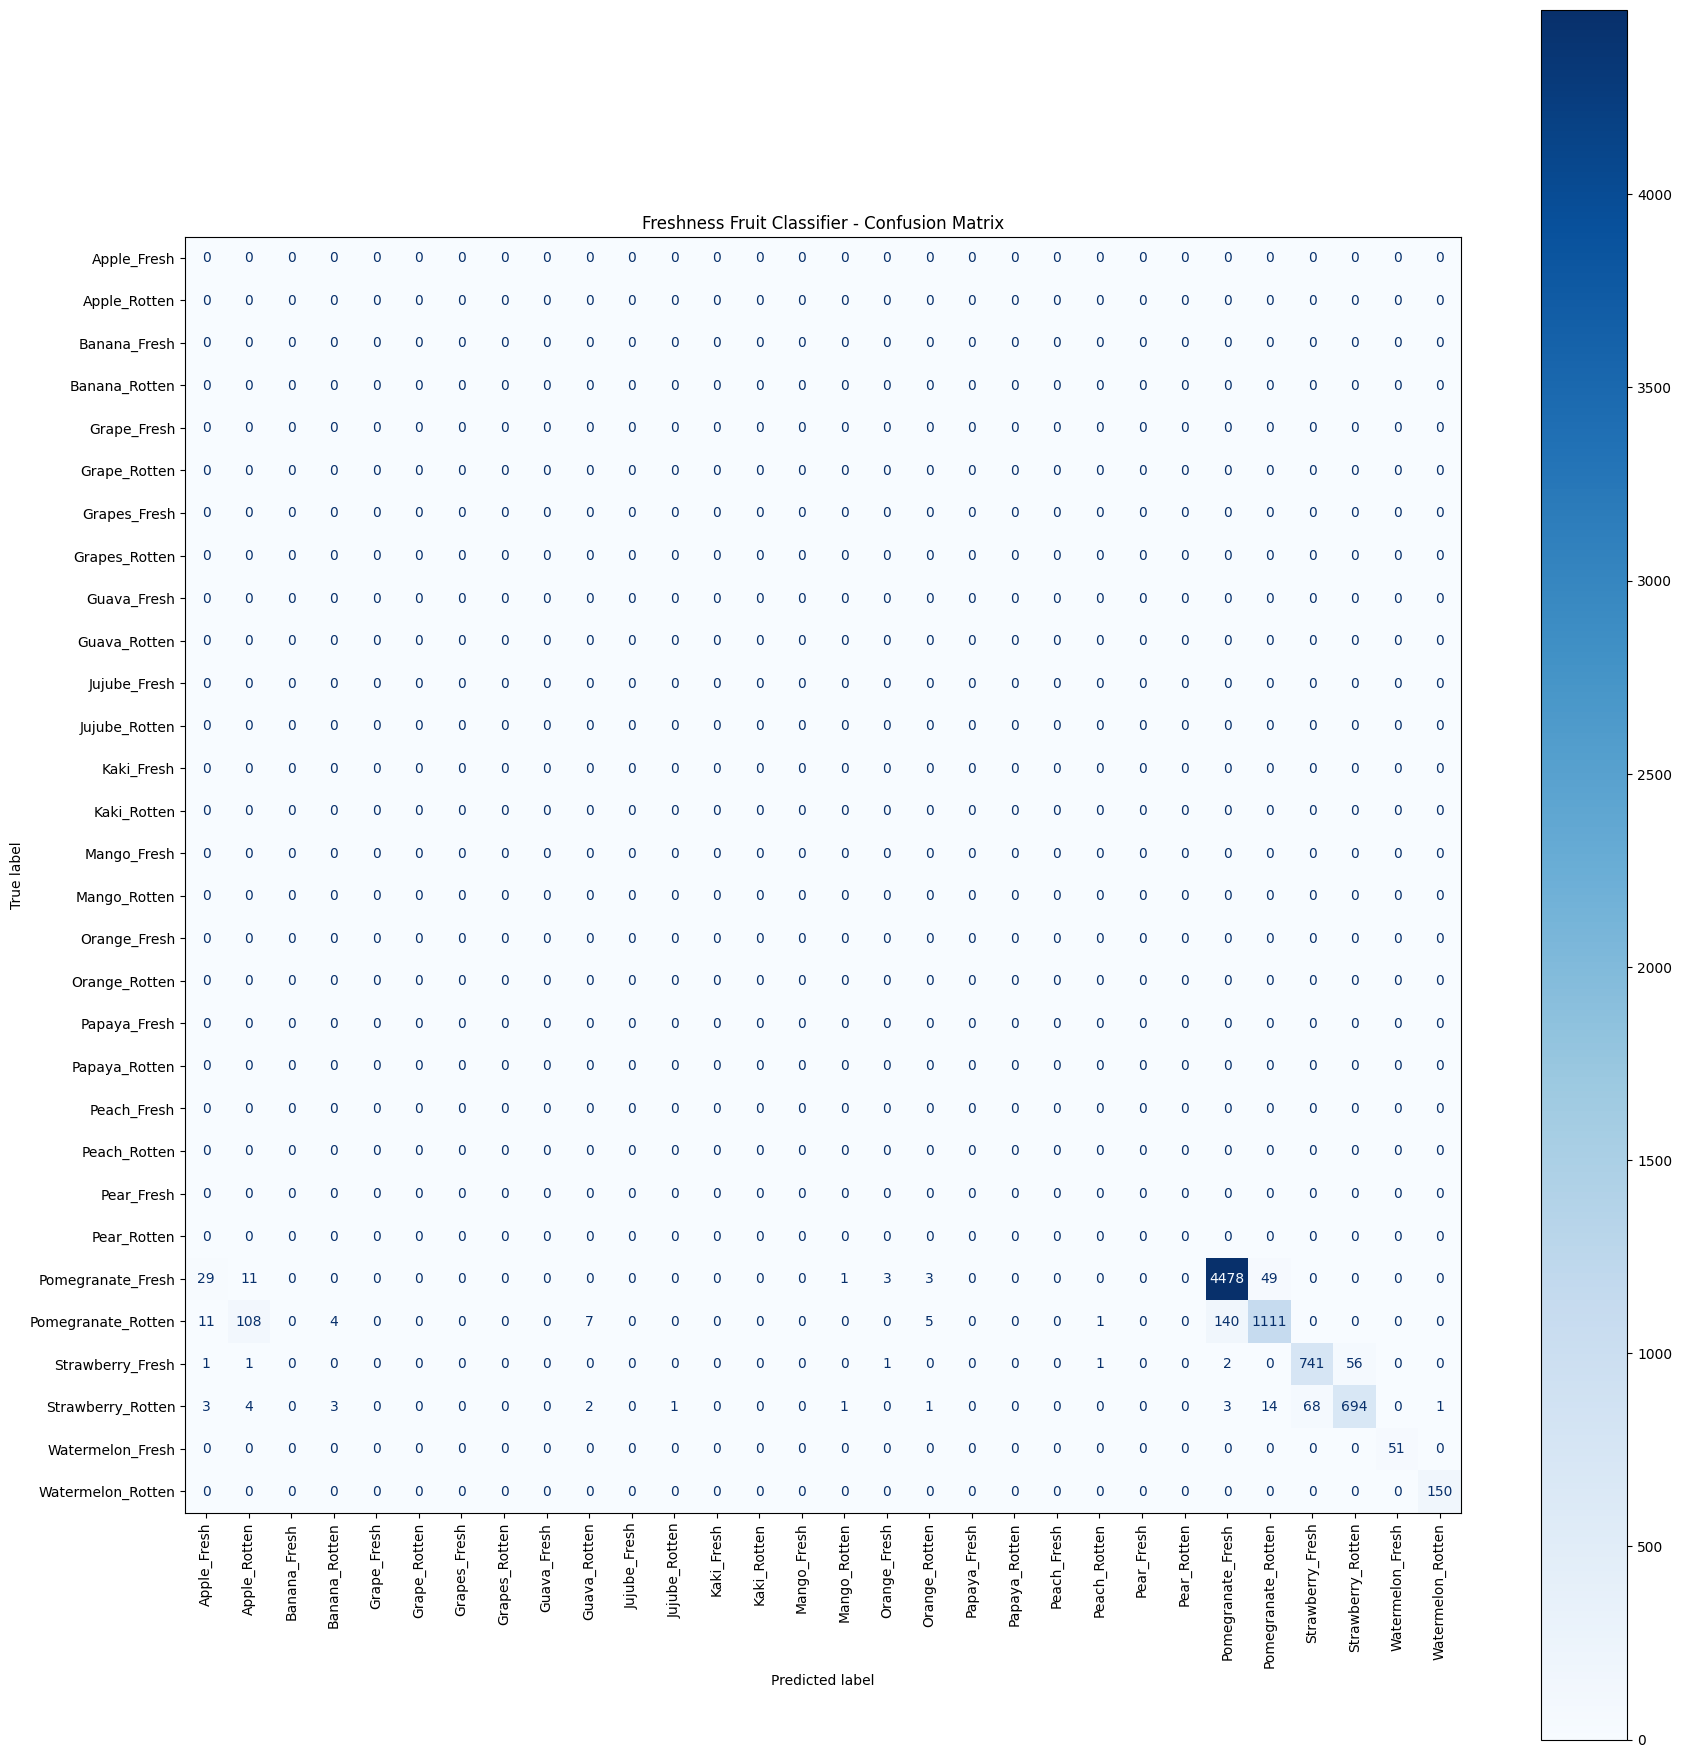

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# Explicitly define all 30 class labels
labels = np.arange(len(class_names))

print("Number of classes:", len(class_names))
print("Number of true labels:", len(y_true))
print("Number of predicted labels:", len(y_pred))

# Classification report
print("\nCLASSIFICATION REPORT")
print("=" * 100)

report = classification_report(
    y_true,
    y_pred,
    labels=labels,
    target_names=class_names,
    digits=4,
    zero_division=0
)

print(report)

# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=labels
)

fig, ax = plt.subplots(figsize=(18, 18))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    xticks_rotation=90,
    values_format='d',
    ax=ax,
    cmap='Blues'
)

plt.title("Freshness Fruit Classifier - Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
from collections import Counter

print("Unique TRUE labels:")
true_counts = Counter(y_true)

for idx, count in sorted(true_counts.items()):
    print(f"{idx:2d}  {class_names[idx]:25s} {count}")

print("\nUnique PREDICTED labels:")
pred_counts = Counter(y_pred)

for idx, count in sorted(pred_counts.items()):
    print(f"{idx:2d}  {class_names[idx]:25s} {count}")

Unique TRUE labels:
24  Pomegranate_Fresh         4574
25  Pomegranate_Rotten        1387
26  Strawberry_Fresh          803
27  Strawberry_Rotten         795
28  Watermelon_Fresh          51
29  Watermelon_Rotten         150

Unique PREDICTED labels:
 0  Apple_Fresh               44
 1  Apple_Rotten              124
 3  Banana_Rotten             7
 9  Guava_Rotten              9
11  Jujube_Rotten             1
15  Mango_Rotten              2
16  Orange_Fresh              4
17  Orange_Rotten             9
21  Peach_Rotten              2
24  Pomegranate_Fresh         4623
25  Pomegranate_Rotten        1174
26  Strawberry_Fresh          809
27  Strawberry_Rotten         750
28  Watermelon_Fresh          51
29  Watermelon_Rotten         151


In [ ]:
print("\nImages per class in the validation dataset:")

for i, class_name in enumerate(class_names):
    count = np.sum(y_true == i)
    print(f"{class_name:25s}: {count}")


Images per class in the validation dataset:
Apple_Fresh              : 0
Apple_Rotten             : 0
Banana_Fresh             : 0
Banana_Rotten            : 0
Grape_Fresh              : 0
Grape_Rotten             : 0
Grapes_Fresh             : 0
Grapes_Rotten            : 0
Guava_Fresh              : 0
Guava_Rotten             : 0
Jujube_Fresh             : 0
Jujube_Rotten            : 0
Kaki_Fresh               : 0
Kaki_Rotten              : 0
Mango_Fresh              : 0
Mango_Rotten             : 0
Orange_Fresh             : 0
Orange_Rotten            : 0
Papaya_Fresh             : 0
Papaya_Rotten            : 0
Peach_Fresh              : 0
Peach_Rotten             : 0
Pear_Fresh               : 0
Pear_Rotten              : 0
Pomegranate_Fresh        : 4574
Pomegranate_Rotten       : 1387
Strawberry_Fresh         : 803
Strawberry_Rotten        : 795
Watermelon_Fresh         : 51
Watermelon_Rotten        : 150


In [ ]:
import os

dataset_path = '/content/drive/MyDrive/Fruit Freshness Project/Freshness44/Freshness44'

print("Number of class folders:", len(os.listdir(dataset_path)))
print()

for class_name in sorted(os.listdir(dataset_path)):
    class_path = os.path.join(dataset_path, class_name)

    if os.path.isdir(class_path):
        files = [
            f for f in os.listdir(class_path)
            if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.webp'))
        ]

        print(f"{class_name:25s}: {len(files)} images")

Number of class folders: 30

Apple_Fresh              : 3468 images
Apple_Rotten             : 4263 images
Banana_Fresh             : 3513 images
Banana_Rotten            : 3605 images
Grape_Fresh              : 227 images
Grape_Rotten             : 288 images
Grapes_Fresh             : 200 images
Grapes_Rotten            : 200 images
Guava_Fresh              : 1352 images
Guava_Rotten             : 1329 images
Jujube_Fresh             : 200 images
Jujube_Rotten            : 200 images
Kaki_Fresh               : 545 images
Kaki_Rotten              : 340 images
Mango_Fresh              : 389 images
Mango_Rotten             : 593 images
Orange_Fresh             : 3164 images
Orange_Rotten            : 3443 images
Papaya_Fresh             : 130 images
Papaya_Rotten            : 413 images
Peach_Fresh              : 425 images
Peach_Rotten             : 584 images
Pear_Fresh               : 504 images
Pear_Rotten              : 100 images
Pomegranate_Fresh        : 6140 images
Pomegranate_

In [ ]:
import os
import random

dataset_path = '/content/drive/MyDrive/Fruit Freshness Project/Freshness44/Freshness44'

random.seed(42)

class_names = sorted([
    d for d in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, d))
])

val_files = []
val_labels = []

for label, class_name in enumerate(class_names):

    class_path = os.path.join(dataset_path, class_name)

    images = [
        os.path.join(class_path, f)
        for f in os.listdir(class_path)
        if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.webp'))
    ]

    random.shuffle(images)

    # 20% of each class
    n_val = max(1, int(len(images) * 0.20))

    selected = images[:n_val]

    val_files.extend(selected)
    val_labels.extend([label] * len(selected))

print("Total validation images:", len(val_files))
print("Total classes:", len(class_names))

print("\nValidation images per class:")
for i, class_name in enumerate(class_names):
    count = sum(1 for x in val_labels if x == i)
    print(f"{class_name:25s}: {count}")

Total validation images: 7750
Total classes: 30

Validation images per class:
Apple_Fresh              : 693
Apple_Rotten             : 852
Banana_Fresh             : 702
Banana_Rotten            : 721
Grape_Fresh              : 45
Grape_Rotten             : 57
Grapes_Fresh             : 40
Grapes_Rotten            : 40
Guava_Fresh              : 270
Guava_Rotten             : 265
Jujube_Fresh             : 40
Jujube_Rotten            : 40
Kaki_Fresh               : 109
Kaki_Rotten              : 68
Mango_Fresh              : 77
Mango_Rotten             : 118
Orange_Fresh             : 632
Orange_Rotten            : 688
Papaya_Fresh             : 26
Papaya_Rotten            : 82
Peach_Fresh              : 85
Peach_Rotten             : 116
Pear_Fresh               : 100
Pear_Rotten              : 20
Pomegranate_Fresh        : 1228
Pomegranate_Rotten       : 277
Strawberry_Fresh         : 160
Strawberry_Rotten        : 159
Watermelon_Fresh         : 10
Watermelon_Rotten        : 30


In [ ]:
import tensorflow as tf

IMG_SIZE = (160, 160)
BATCH_SIZE = 64
NUM_CLASSES = 30

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)

    # Convert integer label -> one-hot label
    label = tf.one_hot(label, depth=NUM_CLASSES)

    return image, label


val_path_ds = tf.data.Dataset.from_tensor_slices(
    (val_files, val_labels)
)

val_ds_proper = (
    val_path_ds
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("Proper validation dataset ready.")

Proper validation dataset ready.


In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import tensorflow as tf

# Make sure model is loaded fresh
model_path = '/content/drive/MyDrive/Fruit Freshness Project/mobilenetv2_improved_best.keras'

best_model = tf.keras.models.load_model(model_path)

y_true = []
y_pred = []

print("Running prediction on the proper 30-class validation set...")

for images, labels in val_ds_proper:
    predictions = best_model.predict(images, verbose=0)

    true_labels = np.argmax(labels.numpy(), axis=1)
    predicted_labels = np.argmax(predictions, axis=1)

    y_true.extend(true_labels)
    y_pred.extend(predicted_labels)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

accuracy = accuracy_score(y_true, y_pred)

print("\n" + "=" * 60)
print(f"PROPER 30-CLASS VALIDATION ACCURACY: {accuracy * 100:.2f}%")
print("=" * 60)

print("\nNumber of validation images:", len(y_true))
print("Number of classes:", len(class_names))

print("\nCLASSIFICATION REPORT")
print("=" * 100)

print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(30),
    target_names=class_names,
    digits=4,
    zero_division=0
))

Running prediction on the proper 30-class validation set...


NameError: name 'val_ds_proper' is not defined

In [ ]:
import os

local_dataset = '/content/Freshness44'

print("Local dataset exists:", os.path.exists(local_dataset))
print("Number of classes:", len(os.listdir(local_dataset)))

for cls in sorted(os.listdir(local_dataset))[:5]:
    print(cls)

Local dataset exists: True
Number of classes: 2
Apple_Fresh
Apple_Rotten


In [ ]:
import os
import shutil
import time

drive_dataset = '/content/drive/MyDrive/Fruit Freshness Project/Freshness44/Freshness44'
local_dataset = '/content/Freshness44'

# Remove incomplete local copy
if os.path.exists(local_dataset):
    print("Removing incomplete local dataset...")
    shutil.rmtree(local_dataset)

# Copy complete dataset
print("Copying complete 30-class dataset to Colab local storage...")
start = time.time()

shutil.copytree(drive_dataset, local_dataset)

elapsed = (time.time() - start) / 60

print(f"\nCopy completed in {elapsed:.2f} minutes.")
print("Local dataset exists:", os.path.exists(local_dataset))
print("Number of classes:", len(os.listdir(local_dataset)))

Removing incomplete local dataset...
Copying complete 30-class dataset to Colab local storage...

Copy completed in 15.74 minutes.
Local dataset exists: True
Number of classes: 30


In [ ]:
classes = sorted([
    d for d in os.listdir('/content/Freshness44')
    if os.path.isdir(os.path.join('/content/Freshness44', d))
])

print("Number of classes:", len(classes))
print("\n".join(classes))

Number of classes: 30
Apple_Fresh
Apple_Rotten
Banana_Fresh
Banana_Rotten
Grape_Fresh
Grape_Rotten
Grapes_Fresh
Grapes_Rotten
Guava_Fresh
Guava_Rotten
Jujube_Fresh
Jujube_Rotten
Kaki_Fresh
Kaki_Rotten
Mango_Fresh
Mango_Rotten
Orange_Fresh
Orange_Rotten
Papaya_Fresh
Papaya_Rotten
Peach_Fresh
Peach_Rotten
Pear_Fresh
Pear_Rotten
Pomegranate_Fresh
Pomegranate_Rotten
Strawberry_Fresh
Strawberry_Rotten
Watermelon_Fresh
Watermelon_Rotten


In [ ]:
import os
import random
import numpy as np
import tensorflow as tf
from sklearn.metrics import accuracy_score, classification_report

# ============================================================
# SETTINGS
# ============================================================

local_dataset = '/content/Freshness44'

IMG_SIZE = (160, 160)
BATCH_SIZE = 64
NUM_CLASSES = 30
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

# ============================================================
# CLASS NAMES
# ============================================================

class_names = sorted([
    d for d in os.listdir(local_dataset)
    if os.path.isdir(os.path.join(local_dataset, d))
])

print("Classes:", len(class_names))

# ============================================================
# CREATE STRATIFIED 20% VALIDATION SET
# ============================================================

val_files = []
val_labels = []

for label, class_name in enumerate(class_names):

    class_path = os.path.join(local_dataset, class_name)

    images = [
        os.path.join(class_path, f)
        for f in os.listdir(class_path)
        if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.webp'))
    ]

    random.shuffle(images)

    n_val = max(1, int(len(images) * 0.20))

    val_files.extend(images[:n_val])
    val_labels.extend([label] * n_val)

print("Total validation images:", len(val_files))

# ============================================================
# LOAD IMAGES FROM LOCAL STORAGE
# ============================================================

def load_image(path, label):

    image = tf.io.read_file(path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image = tf.image.resize(image, IMG_SIZE)

    image = tf.cast(image, tf.float32)

    return image, label


val_ds_fast = (
    tf.data.Dataset
    .from_tensor_slices((val_files, val_labels))
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# ============================================================
# LOAD SAVED MODEL
# ============================================================

model_path = '/content/drive/MyDrive/Fruit Freshness Project/mobilenetv2_improved_best.keras'

print("\nLoading model...")

best_model = tf.keras.models.load_model(model_path)

print("Model loaded successfully.")

# ============================================================
# FAST PREDICTION
# ============================================================

y_true = []
y_pred = []

print("\nRunning predictions from LOCAL storage...")

for images, labels in val_ds_fast:

    predictions = best_model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# ============================================================
# RESULTS
# ============================================================

accuracy = accuracy_score(y_true, y_pred)

print("\n" + "=" * 70)
print(f"PROPER 30-CLASS VALIDATION ACCURACY: {accuracy * 100:.2f}%")
print("=" * 70)

print(f"Validation images: {len(y_true)}")
print(f"Classes: {len(class_names)}")

print("\nCLASSIFICATION REPORT")
print("=" * 100)

print(
    classification_report(
        y_true,
        y_pred,
        labels=np.arange(NUM_CLASSES),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

Classes: 30
Total validation images: 7750

Loading model...
Model loaded successfully.

Running predictions from LOCAL storage...

PROPER 30-CLASS VALIDATION ACCURACY: 91.37%
Validation images: 7750
Classes: 30

CLASSIFICATION REPORT
                    precision    recall  f1-score   support

       Apple_Fresh     0.8633    0.8384    0.8507       693
      Apple_Rotten     0.8698    0.8779    0.8738       852
      Banana_Fresh     0.9884    0.9715    0.9799       702
     Banana_Rotten     0.9673    0.9834    0.9752       721
       Grape_Fresh     1.0000    1.0000    1.0000        45
      Grape_Rotten     1.0000    1.0000    1.0000        57
      Grapes_Fresh     0.8974    0.8750    0.8861        40
     Grapes_Rotten     0.9231    0.9000    0.9114        40
       Guava_Fresh     0.8969    0.8704    0.8835       270
      Guava_Rotten     0.9231    0.8604    0.8906       265
      Jujube_Fresh     0.7778    0.5250    0.6269        40
     Jujube_Rotten     0.5676    0.5250    0.

# **CONFUSION MATRIX**

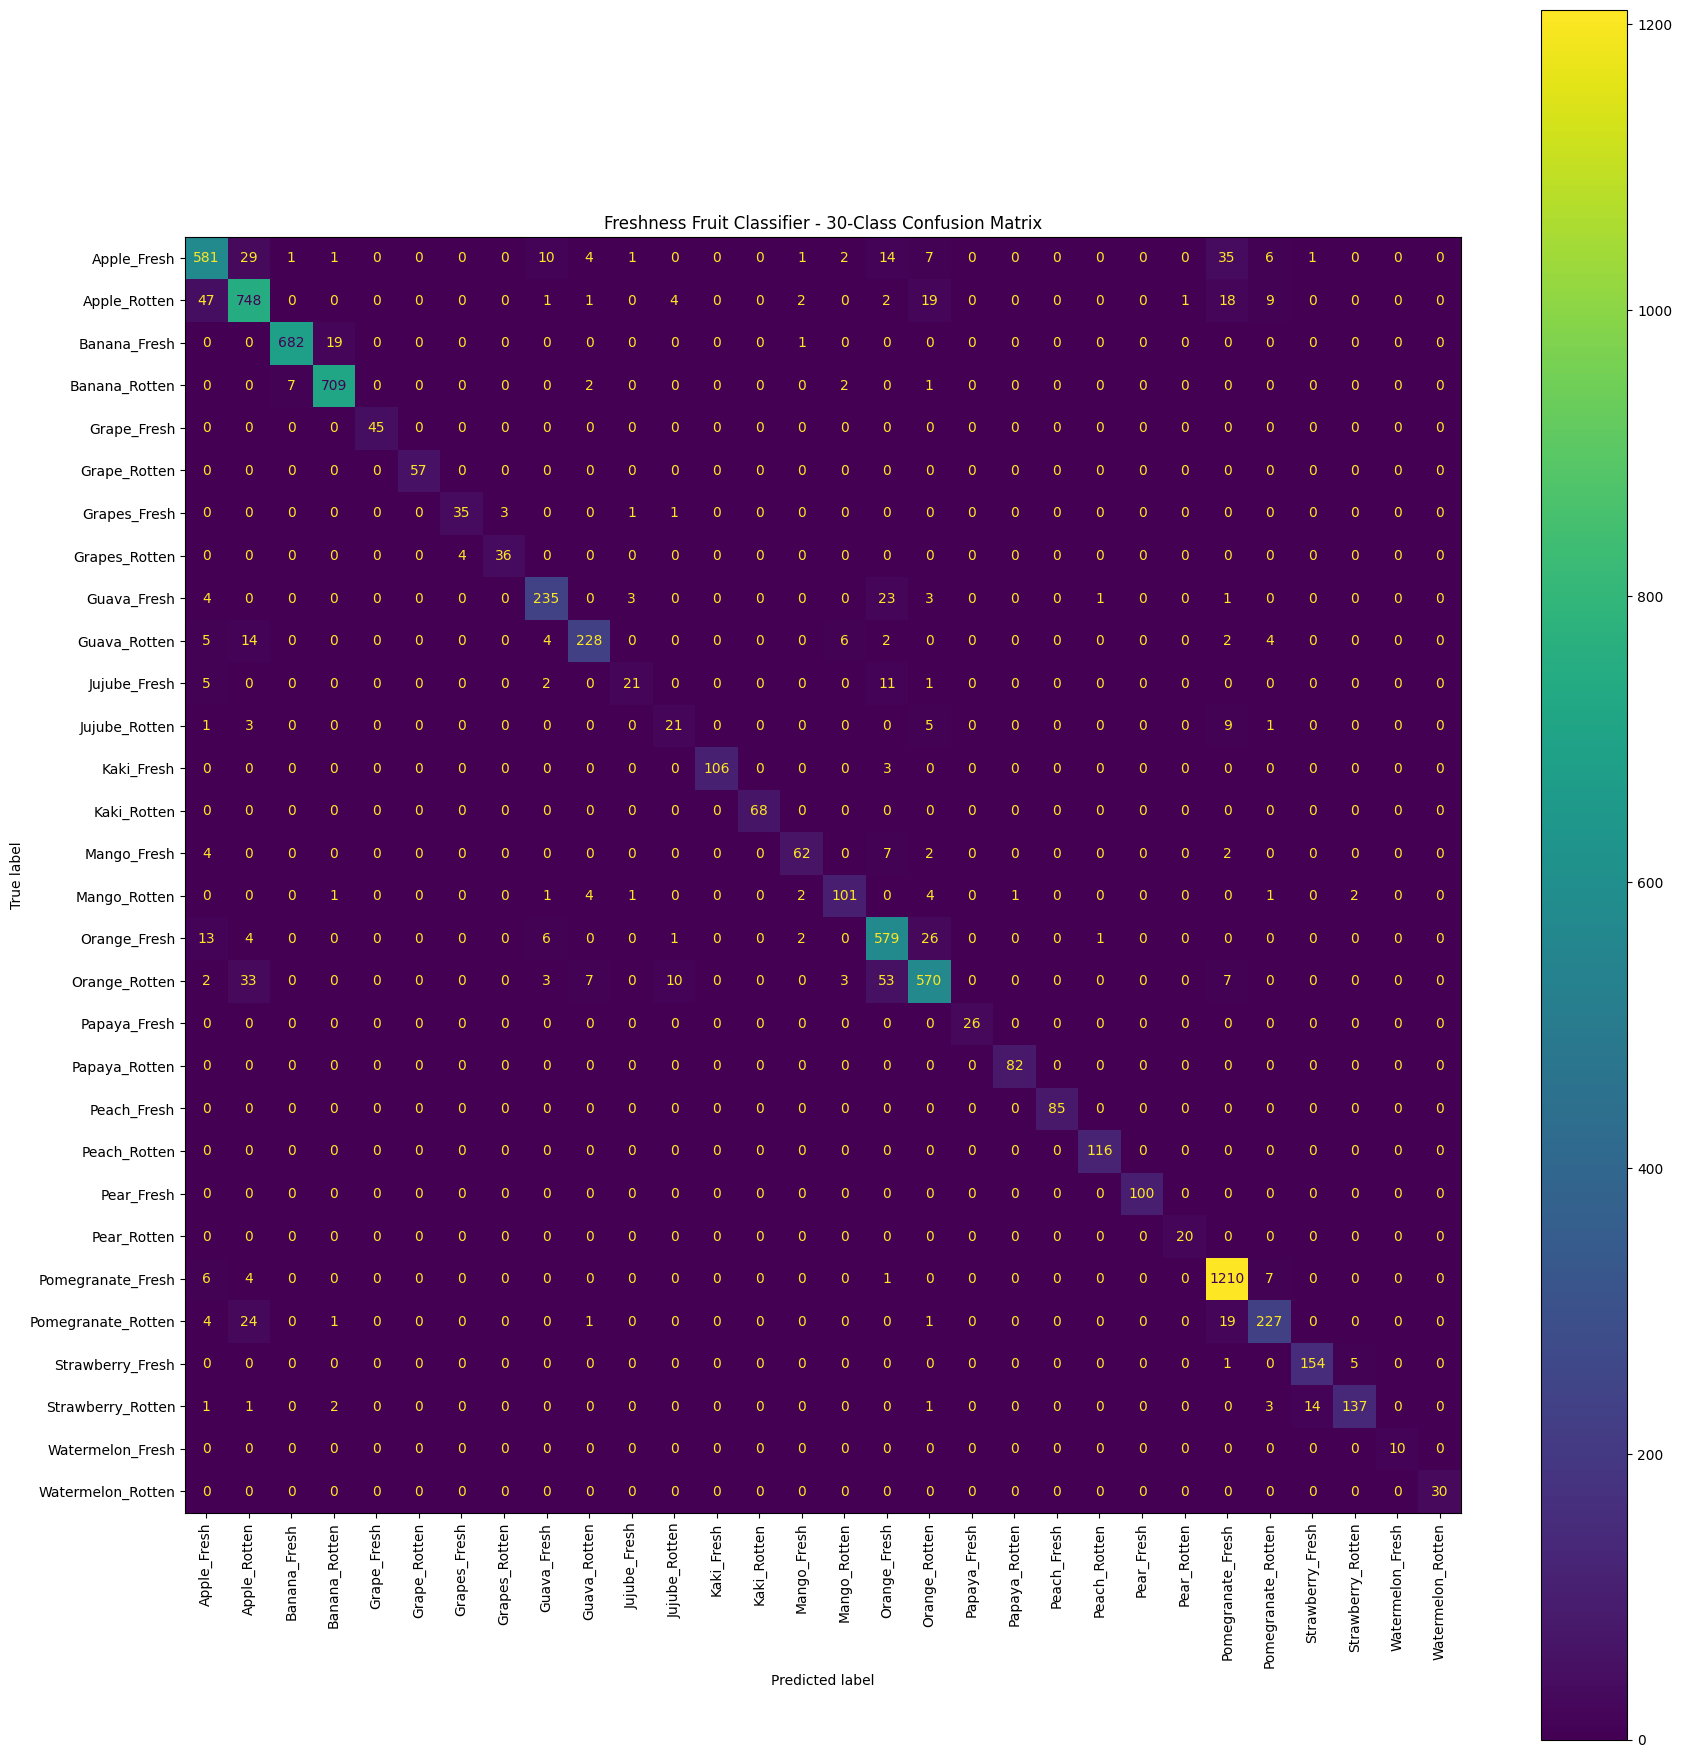

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(class_names))
)

fig, ax = plt.subplots(figsize=(18, 18))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    xticks_rotation=90,
    values_format='d'
)

plt.title("Freshness Fruit Classifier - 30-Class Confusion Matrix")
plt.tight_layout()
plt.show()

# **FINAL PREDICTION CODE**


Loading Freshness Fruit Classifier...
✅ Model loaded successfully!
Number of classes: 30

📤 Please upload a fruit image:


Saving APPLE F.png to APPLE F.png


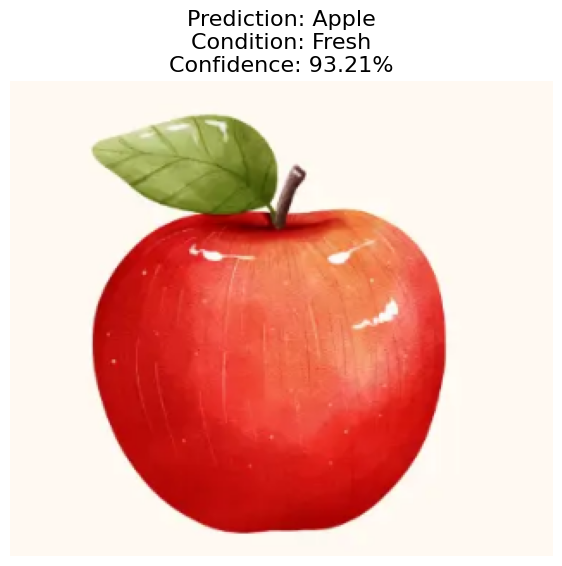


🍎 FRESHNESS FRUIT CLASSIFIER RESULT
Fruit       : Apple
Condition   : Fresh
Confidence  : 93.21%
Class       : Apple_Fresh

🔍 Top 5 Predictions:
---------------------------------------------
1. Apple_Fresh                93.21%
2. Apple_Rotten                5.61%
3. Grapes_Fresh                0.23%
4. Orange_Fresh                0.10%
5. Jujube_Fresh                0.09%

✅ Prediction completed!


In [ ]:
# ============================================================
# 🍎🍌🍓 FRESHNESS FRUIT CLASSIFIER
# FINAL COLAB PREDICTION CELL
# ============================================================

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from PIL import Image

# ============================================================
# 1. MODEL PATH
# ============================================================

MODEL_PATH = '/content/drive/MyDrive/Fruit Freshness Project/mobilenetv2_improved_best.keras'

# ============================================================
# 2. CLASS NAMES
# ============================================================

class_names = [
    'Apple_Fresh',
    'Apple_Rotten',
    'Banana_Fresh',
    'Banana_Rotten',
    'Grape_Fresh',
    'Grape_Rotten',
    'Grapes_Fresh',
    'Grapes_Rotten',
    'Guava_Fresh',
    'Guava_Rotten',
    'Jujube_Fresh',
    'Jujube_Rotten',
    'Kaki_Fresh',
    'Kaki_Rotten',
    'Mango_Fresh',
    'Mango_Rotten',
    'Orange_Fresh',
    'Orange_Rotten',
    'Papaya_Fresh',
    'Papaya_Rotten',
    'Peach_Fresh',
    'Peach_Rotten',
    'Pear_Fresh',
    'Pear_Rotten',
    'Pomegranate_Fresh',
    'Pomegranate_Rotten',
    'Strawberry_Fresh',
    'Strawberry_Rotten',
    'Watermelon_Fresh',
    'Watermelon_Rotten'
]

# ============================================================
# 3. LOAD MODEL
# ============================================================

print("Loading Freshness Fruit Classifier...")

model = tf.keras.models.load_model(MODEL_PATH)

print("✅ Model loaded successfully!")
print("Number of classes:", len(class_names))

# ============================================================
# 4. UPLOAD IMAGE
# ============================================================

print("\n📤 Please upload a fruit image:")

uploaded = files.upload()

if len(uploaded) == 0:
    raise ValueError("No image was uploaded.")

image_path = list(uploaded.keys())[0]

# ============================================================
# 5. LOAD & PREPROCESS IMAGE
# ============================================================

IMG_SIZE = (160, 160)

image = Image.open(image_path).convert('RGB')

original_image = image.copy()

image_resized = image.resize(IMG_SIZE)

image_array = np.array(image_resized, dtype=np.float32)

# Add batch dimension
image_input = np.expand_dims(image_array, axis=0)

# ============================================================
# 6. PREDICTION
# ============================================================

predictions = model.predict(image_input, verbose=0)[0]

predicted_index = np.argmax(predictions)

predicted_class = class_names[predicted_index]

confidence = predictions[predicted_index] * 100

# ============================================================
# 7. SEPARATE FRUIT + CONDITION
# ============================================================

if predicted_class.endswith('_Fresh'):
    condition = 'Fresh'
else:
    condition = 'Rotten'

fruit_name = predicted_class.rsplit('_', 1)[0]

# ============================================================
# 8. TOP 5 PREDICTIONS
# ============================================================

top_5_indices = np.argsort(predictions)[-5:][::-1]

# ============================================================
# 9. DISPLAY IMAGE
# ============================================================

plt.figure(figsize=(7, 7))

plt.imshow(original_image)
plt.axis('off')

plt.title(
    f"Prediction: {fruit_name}\n"
    f"Condition: {condition}\n"
    f"Confidence: {confidence:.2f}%",
    fontsize=16
)

plt.show()

# ============================================================
# 10. FINAL RESULT
# ============================================================

print("\n" + "=" * 60)
print("🍎 FRESHNESS FRUIT CLASSIFIER RESULT")
print("=" * 60)

print(f"Fruit       : {fruit_name}")
print(f"Condition   : {condition}")
print(f"Confidence  : {confidence:.2f}%")
print(f"Class       : {predicted_class}")

print("=" * 60)

# ============================================================
# 11. TOP 5 PREDICTIONS
# ============================================================

print("\n🔍 Top 5 Predictions:")
print("-" * 45)

for rank, index in enumerate(top_5_indices, start=1):

    class_name = class_names[index]
    probability = predictions[index] * 100

    print(
        f"{rank}. {class_name:25s} "
        f"{probability:6.2f}%"
    )

print("\n✅ Prediction completed!")

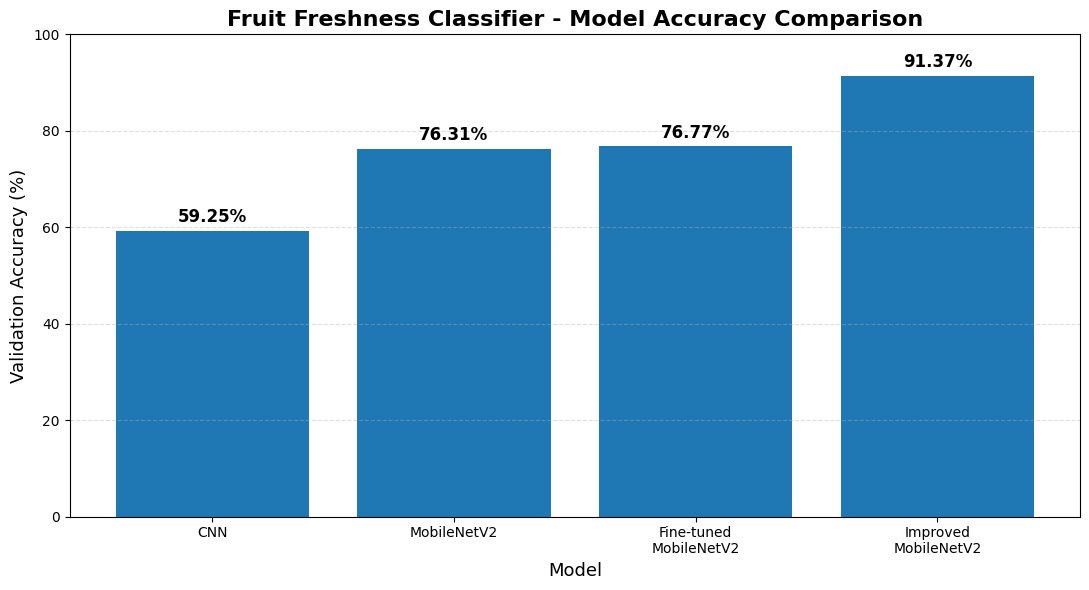

✅ Graph created successfully!
📁 Saved at: /content/model_accuracy_comparison.png


In [ ]:
# ============================================================
# 📊 FRUIT FRESHNESS PROJECT
# MODEL ACCURACY COMPARISON GRAPH
# ============================================================

import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. MODEL RESULTS
# ------------------------------------------------------------

models = [
    "CNN",
    "MobileNetV2",
    "Fine-tuned\nMobileNetV2",
    "Improved\nMobileNetV2"
]

accuracy = [
    59.25,
    76.31,
    76.77,
    91.37
]

# ------------------------------------------------------------
# 2. CREATE GRAPH
# ------------------------------------------------------------

plt.figure(figsize=(11, 6))

bars = plt.bar(models, accuracy)

# ------------------------------------------------------------
# 3. ADD ACCURACY VALUES ON TOP
# ------------------------------------------------------------

for bar, value in zip(bars, accuracy):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}%",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold"
    )

# ------------------------------------------------------------
# 4. GRAPH SETTINGS
# ------------------------------------------------------------

plt.title(
    "Fruit Freshness Classifier - Model Accuracy Comparison",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Model", fontsize=13)
plt.ylabel("Validation Accuracy (%)", fontsize=13)

plt.ylim(0, 100)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()

# ------------------------------------------------------------
# 5. SAVE GRAPH
# ------------------------------------------------------------

graph_path = "/content/model_accuracy_comparison.png"

plt.savefig(
    graph_path,
    dpi=300,
    bbox_inches="tight"
)

# ------------------------------------------------------------
# 6. DISPLAY
# ------------------------------------------------------------

plt.show()

print("✅ Graph created successfully!")
print(f"📁 Saved at: {graph_path}")

# **TEST OTHER FRUITS**

Loading Freshness Fruit Classifier...
✅ Model loaded successfully!
Number of classes: 30

📤 Please upload a fruit image:


Saving BANANA F.png to BANANA F.png


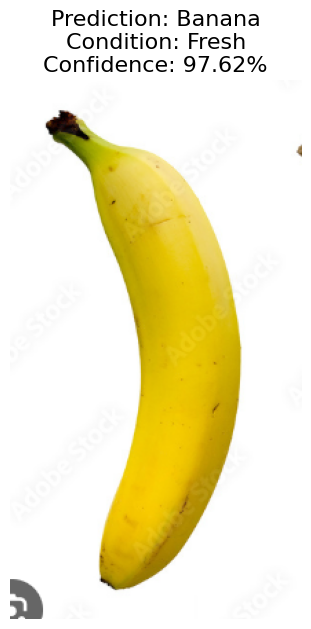


🍎 FRESHNESS FRUIT CLASSIFIER RESULT
Fruit       : Banana
Condition   : Fresh
Confidence  : 97.62%
Class       : Banana_Fresh

🔍 Top 5 Predictions:
---------------------------------------------
1. Banana_Fresh               97.62%
2. Grapes_Rotten               0.69%
3. Grapes_Fresh                0.22%
4. Pear_Fresh                  0.22%
5. Jujube_Fresh                0.16%

✅ Prediction completed!


In [ ]:
# ============================================================
# 🍎🍌🍓 FRESHNESS FRUIT CLASSIFIER
# FINAL COLAB PREDICTION CELL
# ============================================================

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from PIL import Image

# ============================================================
# 1. MODEL PATH
# ============================================================

MODEL_PATH = '/content/drive/MyDrive/Fruit Freshness Project/mobilenetv2_improved_best.keras'

# ============================================================
# 2. CLASS NAMES
# ============================================================

class_names = [
    'Apple_Fresh',
    'Apple_Rotten',
    'Banana_Fresh',
    'Banana_Rotten',
    'Grape_Fresh',
    'Grape_Rotten',
    'Grapes_Fresh',
    'Grapes_Rotten',
    'Guava_Fresh',
    'Guava_Rotten',
    'Jujube_Fresh',
    'Jujube_Rotten',
    'Kaki_Fresh',
    'Kaki_Rotten',
    'Mango_Fresh',
    'Mango_Rotten',
    'Orange_Fresh',
    'Orange_Rotten',
    'Papaya_Fresh',
    'Papaya_Rotten',
    'Peach_Fresh',
    'Peach_Rotten',
    'Pear_Fresh',
    'Pear_Rotten',
    'Pomegranate_Fresh',
    'Pomegranate_Rotten',
    'Strawberry_Fresh',
    'Strawberry_Rotten',
    'Watermelon_Fresh',
    'Watermelon_Rotten'
]

# ============================================================
# 3. LOAD MODEL
# ============================================================

print("Loading Freshness Fruit Classifier...")

model = tf.keras.models.load_model(MODEL_PATH)

print("✅ Model loaded successfully!")
print("Number of classes:", len(class_names))

# ============================================================
# 4. UPLOAD IMAGE
# ============================================================

print("\n📤 Please upload a fruit image:")

uploaded = files.upload()

if len(uploaded) == 0:
    raise ValueError("No image was uploaded.")

image_path = list(uploaded.keys())[0]

# ============================================================
# 5. LOAD & PREPROCESS IMAGE
# ============================================================

IMG_SIZE = (160, 160)

image = Image.open(image_path).convert('RGB')

original_image = image.copy()

image_resized = image.resize(IMG_SIZE)

image_array = np.array(image_resized, dtype=np.float32)

# Add batch dimension
image_input = np.expand_dims(image_array, axis=0)

# ============================================================
# 6. PREDICTION
# ============================================================

predictions = model.predict(image_input, verbose=0)[0]

predicted_index = np.argmax(predictions)

predicted_class = class_names[predicted_index]

confidence = predictions[predicted_index] * 100

# ============================================================
# 7. SEPARATE FRUIT + CONDITION
# ============================================================

if predicted_class.endswith('_Fresh'):
    condition = 'Fresh'
else:
    condition = 'Rotten'

fruit_name = predicted_class.rsplit('_', 1)[0]

# ============================================================
# 8. TOP 5 PREDICTIONS
# ============================================================

top_5_indices = np.argsort(predictions)[-5:][::-1]

# ============================================================
# 9. DISPLAY IMAGE
# ============================================================

plt.figure(figsize=(7, 7))

plt.imshow(original_image)
plt.axis('off')

plt.title(
    f"Prediction: {fruit_name}\n"
    f"Condition: {condition}\n"
    f"Confidence: {confidence:.2f}%",
    fontsize=16
)

plt.show()

# ============================================================
# 10. FINAL RESULT
# ============================================================

print("\n" + "=" * 60)
print("🍎 FRESHNESS FRUIT CLASSIFIER RESULT")
print("=" * 60)

print(f"Fruit       : {fruit_name}")
print(f"Condition   : {condition}")
print(f"Confidence  : {confidence:.2f}%")
print(f"Class       : {predicted_class}")

print("=" * 60)

# ============================================================
# 11. TOP 5 PREDICTIONS
# ============================================================

print("\n🔍 Top 5 Predictions:")
print("-" * 45)

for rank, index in enumerate(top_5_indices, start=1):

    class_name = class_names[index]
    probability = predictions[index] * 100

    print(
        f"{rank}. {class_name:25s} "
        f"{probability:6.2f}%"
    )

print("\n✅ Prediction completed!")

Loading Freshness Fruit Classifier...
✅ Model loaded successfully!
Number of classes: 30

📤 Please upload a fruit image:


Saving ORANGE R.png to ORANGE R.png


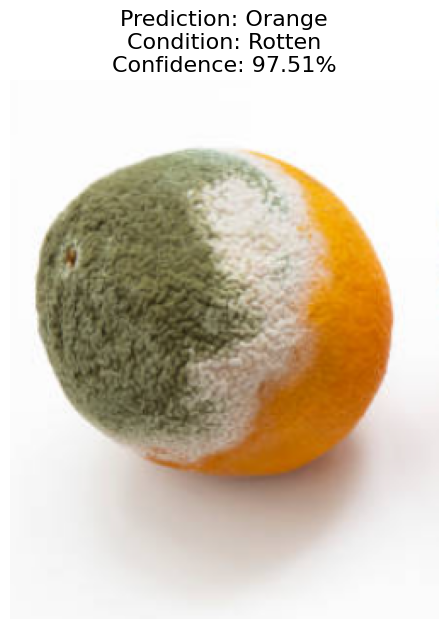


🍎 FRESHNESS FRUIT CLASSIFIER RESULT
Fruit       : Orange
Condition   : Rotten
Confidence  : 97.51%
Class       : Orange_Rotten

🔍 Top 5 Predictions:
---------------------------------------------
1. Orange_Rotten              97.51%
2. Mango_Rotten                0.54%
3. Peach_Rotten                0.47%
4. Orange_Fresh                0.36%
5. Kaki_Fresh                  0.19%

✅ Prediction completed!


In [ ]:
# ============================================================
# 🍎🍌🍓 FRESHNESS FRUIT CLASSIFIER
# FINAL COLAB PREDICTION CELL
# ============================================================

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from PIL import Image

# ============================================================
# 1. MODEL PATH
# ============================================================

MODEL_PATH = '/content/drive/MyDrive/Fruit Freshness Project/mobilenetv2_improved_best.keras'

# ============================================================
# 2. CLASS NAMES
# ============================================================

class_names = [
    'Apple_Fresh',
    'Apple_Rotten',
    'Banana_Fresh',
    'Banana_Rotten',
    'Grape_Fresh',
    'Grape_Rotten',
    'Grapes_Fresh',
    'Grapes_Rotten',
    'Guava_Fresh',
    'Guava_Rotten',
    'Jujube_Fresh',
    'Jujube_Rotten',
    'Kaki_Fresh',
    'Kaki_Rotten',
    'Mango_Fresh',
    'Mango_Rotten',
    'Orange_Fresh',
    'Orange_Rotten',
    'Papaya_Fresh',
    'Papaya_Rotten',
    'Peach_Fresh',
    'Peach_Rotten',
    'Pear_Fresh',
    'Pear_Rotten',
    'Pomegranate_Fresh',
    'Pomegranate_Rotten',
    'Strawberry_Fresh',
    'Strawberry_Rotten',
    'Watermelon_Fresh',
    'Watermelon_Rotten'
]

# ============================================================
# 3. LOAD MODEL
# ============================================================

print("Loading Freshness Fruit Classifier...")

model = tf.keras.models.load_model(MODEL_PATH)

print("✅ Model loaded successfully!")
print("Number of classes:", len(class_names))

# ============================================================
# 4. UPLOAD IMAGE
# ============================================================

print("\n📤 Please upload a fruit image:")

uploaded = files.upload()

if len(uploaded) == 0:
    raise ValueError("No image was uploaded.")

image_path = list(uploaded.keys())[0]

# ============================================================
# 5. LOAD & PREPROCESS IMAGE
# ============================================================

IMG_SIZE = (160, 160)

image = Image.open(image_path).convert('RGB')

original_image = image.copy()

image_resized = image.resize(IMG_SIZE)

image_array = np.array(image_resized, dtype=np.float32)

# Add batch dimension
image_input = np.expand_dims(image_array, axis=0)

# ============================================================
# 6. PREDICTION
# ============================================================

predictions = model.predict(image_input, verbose=0)[0]

predicted_index = np.argmax(predictions)

predicted_class = class_names[predicted_index]

confidence = predictions[predicted_index] * 100

# ============================================================
# 7. SEPARATE FRUIT + CONDITION
# ============================================================

if predicted_class.endswith('_Fresh'):
    condition = 'Fresh'
else:
    condition = 'Rotten'

fruit_name = predicted_class.rsplit('_', 1)[0]

# ============================================================
# 8. TOP 5 PREDICTIONS
# ============================================================

top_5_indices = np.argsort(predictions)[-5:][::-1]

# ============================================================
# 9. DISPLAY IMAGE
# ============================================================

plt.figure(figsize=(7, 7))

plt.imshow(original_image)
plt.axis('off')

plt.title(
    f"Prediction: {fruit_name}\n"
    f"Condition: {condition}\n"
    f"Confidence: {confidence:.2f}%",
    fontsize=16
)

plt.show()

# ============================================================
# 10. FINAL RESULT
# ============================================================

print("\n" + "=" * 60)
print("🍎 FRESHNESS FRUIT CLASSIFIER RESULT")
print("=" * 60)

print(f"Fruit       : {fruit_name}")
print(f"Condition   : {condition}")
print(f"Confidence  : {confidence:.2f}%")
print(f"Class       : {predicted_class}")

print("=" * 60)

# ============================================================
# 11. TOP 5 PREDICTIONS
# ============================================================

print("\n🔍 Top 5 Predictions:")
print("-" * 45)

for rank, index in enumerate(top_5_indices, start=1):

    class_name = class_names[index]
    probability = predictions[index] * 100

    print(
        f"{rank}. {class_name:25s} "
        f"{probability:6.2f}%"
    )

print("\n✅ Prediction completed!")

# **25 EPOCHS WORKING**

In [ ]:
# ============================================================
# 🚀 FINAL IMPROVED MOBILENETV2 - 25 EPOCHS
# ============================================================

import tensorflow as tf
import os

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

DATA_DIR = "/content/Freshness44"

MODEL_PATH = (
    "/content/drive/MyDrive/Fruit Freshness Project/"
    "mobilenetv2_improved_best.keras"
)

# ------------------------------------------------------------
# 2. SETTINGS
# ------------------------------------------------------------

IMG_SIZE = (160, 160)
BATCH_SIZE = 32
NUM_CLASSES = 30

# ------------------------------------------------------------
# 3. LOAD DATASET
# ------------------------------------------------------------

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.20,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.20,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)

# Performance
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)

# ------------------------------------------------------------
# 4. DATA AUGMENTATION
# ------------------------------------------------------------

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomContrast(0.10),
], name="data_augmentation")

# ------------------------------------------------------------
# 5. MOBILE NET V2
# ------------------------------------------------------------

base_model = tf.keras.applications.MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(160, 160, 3)
)

base_model.trainable = False

# ------------------------------------------------------------
# 6. MODEL
# ------------------------------------------------------------

inputs = tf.keras.Input(shape=(160, 160, 3))

x = data_augmentation(inputs)

# MobileNetV2 preprocessing
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

x = base_model(x, training=False)

x = tf.keras.layers.GlobalAveragePooling2D()(x)

x = tf.keras.layers.BatchNormalization()(x)

x = tf.keras.layers.Dropout(0.30)(x)

outputs = tf.keras.layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

model = tf.keras.Model(inputs, outputs)

# ------------------------------------------------------------
# 7. STAGE 1 TRAINING
# ------------------------------------------------------------

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("🚀 Starting final 25-epoch training...")
print("Stage 1: Frozen MobileNetV2")

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    callbacks=[
        tf.keras.callbacks.ModelCheckpoint(
            MODEL_PATH,
            monitor="val_accuracy",
            save_best_only=True,
            mode="max",
            verbose=1
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_accuracy",
            patience=5,
            restore_best_weights=True,
            mode="max",
            verbose=1
        )
    ]
)

print("\n✅ Training completed!")
print("Best model saved at:")
print(MODEL_PATH)

FileNotFoundError: [Errno 2] No such file or directory: '/content/Freshness44'

In [ ]:
from google.colab import drive
import os

drive.mount('/content/drive')

DATA_DIR = "/content/drive/MyDrive/Fruit Freshness Project/Freshness44/Freshness44"

print("Dataset exists:", os.path.exists(DATA_DIR))

if os.path.exists(DATA_DIR):
    print("Classes:", len([
        x for x in os.listdir(DATA_DIR)
        if os.path.isdir(os.path.join(DATA_DIR, x))
    ]))
else:
    print("❌ Dataset path not found!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset exists: True
Classes: 30


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Fruit Freshness Project"

print("📁 Checking saved models...\n")

for file in os.listdir(PROJECT_DIR):
    if file.endswith(".keras"):
        path = os.path.join(PROJECT_DIR, file)
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"✅ {file}  —  {size_mb:.2f} MB")

📁 Checking saved models...

✅ fruit_freshness_checkpoint.keras  —  31.63 MB
✅ mobilenetv2_best.keras  —  13.03 MB
✅ mobilenetv2_finetuned_best.keras  —  24.56 MB
✅ FINAL_Fruit_Freshness_MobileNetV2.keras  —  24.56 MB
✅ mobilenetv2_improved_best.keras  —  9.67 MB


In [ ]:
# ============================================================
# 🔍 CHECK SAVED IMPROVED MODEL
# No training — only inspection
# ============================================================

import tensorflow as tf
import os

MODEL_PATH = (
    "/content/drive/MyDrive/Fruit Freshness Project/"
    "mobilenetv2_improved_best.keras"
)

print("🔍 Checking saved model...\n")

# Load model
model = tf.keras.models.load_model(MODEL_PATH)

print("✅ Model loaded successfully!")
print("-" * 50)

print("Input shape  :", model.input_shape)
print("Output shape :", model.output_shape)
print("Total layers :", len(model.layers))
print("Model file   :", MODEL_PATH)

# Model size
size_mb = os.path.getsize(MODEL_PATH) / (1024 * 1024)
print(f"Model size   : {size_mb:.2f} MB")

print("-" * 50)
print("✅ No training was performed.")
print("✅ No epochs were run.")

🔍 Checking saved model...

✅ Model loaded successfully!
--------------------------------------------------
Input shape  : (None, 160, 160, 3)
Output shape : (None, 30)
Total layers : 7
Model file   : /content/drive/MyDrive/Fruit Freshness Project/mobilenetv2_improved_best.keras
Model size   : 9.67 MB
--------------------------------------------------
✅ No training was performed.
✅ No epochs were run.


In [ ]:
# ============================================================
# 🔍 CHECK EXISTING TRAINING HISTORY
# ============================================================

if "history" in globals():

    print("✅ Training history found!")

    print("Epochs recorded:", len(history.history["accuracy"]))

    print("\nAccuracy:")
    print(history.history["accuracy"])

    print("\nValidation Accuracy:")
    print(history.history["val_accuracy"])

else:
    print("❌ Training history is not available in this runtime.")
    print("The previous runtime/session was reset.")

❌ Training history is not available in this runtime.
The previous runtime/session was reset.


In [ ]:
# ============================================================
# 🍎 FRUIT FRESHNESS PROJECT
# SAVE FINAL EVALUATION RESULTS
# CSV + EXCEL
# ============================================================

import pandas as pd
import os

# ------------------------------------------------------------
# FINAL VERIFIED RESULTS
# ------------------------------------------------------------

results = {
    "Metric": [
        "Validation Images",
        "Number of Classes",
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Weighted Precision",
        "Weighted Recall",
        "Weighted F1"
    ],
    "Value": [
        7750,
        30,
        0.9137,
        0.9255,
        0.9078,
        0.9154,
        0.9136,
        0.9137,
        0.9129
    ]
}

summary_df = pd.DataFrame(results)

# ------------------------------------------------------------
# CLASSIFICATION REPORT
# ------------------------------------------------------------

classification_data = {
    "Class": [
        "Apple_Fresh", "Apple_Rotten",
        "Banana_Fresh", "Banana_Rotten",
        "Grape_Fresh", "Grape_Rotten",
        "Grapes_Fresh", "Grapes_Rotten",
        "Guava_Fresh", "Guava_Rotten",
        "Jujube_Fresh", "Jujube_Rotten",
        "Kaki_Fresh", "Kaki_Rotten",
        "Mango_Fresh", "Mango_Rotten",
        "Orange_Fresh", "Orange_Rotten",
        "Papaya_Fresh", "Papaya_Rotten",
        "Peach_Fresh", "Peach_Rotten",
        "Pear_Fresh", "Pear_Rotten",
        "Pomegranate_Fresh", "Pomegranate_Rotten",
        "Strawberry_Fresh", "Strawberry_Rotten",
        "Watermelon_Fresh", "Watermelon_Rotten"
    ],

    "Precision": [
        0.8633, 0.8698,
        0.9884, 0.9673,
        1.0000, 1.0000,
        0.8974, 0.9231,
        0.8969, 0.9231,
        0.7778, 0.5676,
        1.0000, 1.0000,
        0.8857, 0.8860,
        0.8331, 0.8906,
        1.0000, 0.9880,
        1.0000, 0.9831,
        1.0000, 0.9524,
        0.9279, 0.8798,
        0.9112, 0.9514,
        1.0000, 1.0000
    ],

    "Recall": [
        0.8384, 0.8779,
        0.9715, 0.9834,
        1.0000, 1.0000,
        0.8750, 0.9000,
        0.8704, 0.8604,
        0.5250, 0.5250,
        0.9725, 1.0000,
        0.8052, 0.8559,
        0.9161, 0.8285,
        1.0000, 1.0000,
        1.0000, 1.0000,
        1.0000, 1.0000,
        0.9853, 0.8195,
        0.9625, 0.8616,
        1.0000, 1.0000
    ],

    "F1-Score": [
        0.8507, 0.8738,
        0.9799, 0.9752,
        1.0000, 1.0000,
        0.8861, 0.9114,
        0.8835, 0.8906,
        0.6269, 0.5455,
        0.9860, 1.0000,
        0.8435, 0.8707,
        0.8726, 0.8584,
        1.0000, 0.9939,
        1.0000, 0.9915,
        1.0000, 0.9756,
        0.9558, 0.8486,
        0.9362, 0.9043,
        1.0000, 1.0000
    ],

    "Support": [
        693, 852,
        702, 721,
        45, 57,
        40, 40,
        270, 265,
        40, 40,
        109, 68,
        77, 118,
        632, 688,
        26, 82,
        85, 116,
        100, 20,
        1228, 277,
        160, 159,
        10, 30
    ]
}

classification_df = pd.DataFrame(classification_data)

# ------------------------------------------------------------
# MODEL COMPARISON
# ------------------------------------------------------------

model_comparison_df = pd.DataFrame({
    "Model": [
        "CNN",
        "MobileNetV2",
        "Fine-tuned MobileNetV2",
        "Improved MobileNetV2"
    ],
    "Validation Accuracy (%)": [
        59.25,
        76.31,
        76.77,
        91.37
    ]
})

# ------------------------------------------------------------
# SAVE LOCATION
# ------------------------------------------------------------

OUTPUT_DIR = "/content/drive/MyDrive/Fruit Freshness Project"

csv_path = os.path.join(
    OUTPUT_DIR,
    "final_evaluation_results.csv"
)

excel_path = os.path.join(
    OUTPUT_DIR,
    "final_evaluation_results.xlsx"
)

# ------------------------------------------------------------
# SAVE CSV
# ------------------------------------------------------------

summary_df.to_csv(csv_path, index=False)

# ------------------------------------------------------------
# SAVE EXCEL WITH 3 SHEETS
# ------------------------------------------------------------

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:

    summary_df.to_excel(
        writer,
        sheet_name="Final Metrics",
        index=False
    )

    classification_df.to_excel(
        writer,
        sheet_name="Classification Report",
        index=False
    )

    model_comparison_df.to_excel(
        writer,
        sheet_name="Model Comparison",
        index=False
    )

# ------------------------------------------------------------
# CONFIRMATION
# ------------------------------------------------------------

print("=" * 60)
print("✅ FINAL RESULTS SAVED SUCCESSFULLY")
print("=" * 60)

print("\n📄 CSV:")
print(csv_path)

print("\n📊 Excel:")
print(excel_path)

print("\n📌 Final Accuracy: 91.37%")
print("📌 Macro F1-Score: 91.54%")
print("📌 Validation Images: 7,750")
print("📌 Classes: 30")

✅ FINAL RESULTS SAVED SUCCESSFULLY

📄 CSV:
/content/drive/MyDrive/Fruit Freshness Project/final_evaluation_results.csv

📊 Excel:
/content/drive/MyDrive/Fruit Freshness Project/final_evaluation_results.xlsx

📌 Final Accuracy: 91.37%
📌 Macro F1-Score: 91.54%
📌 Validation Images: 7,750
📌 Classes: 30


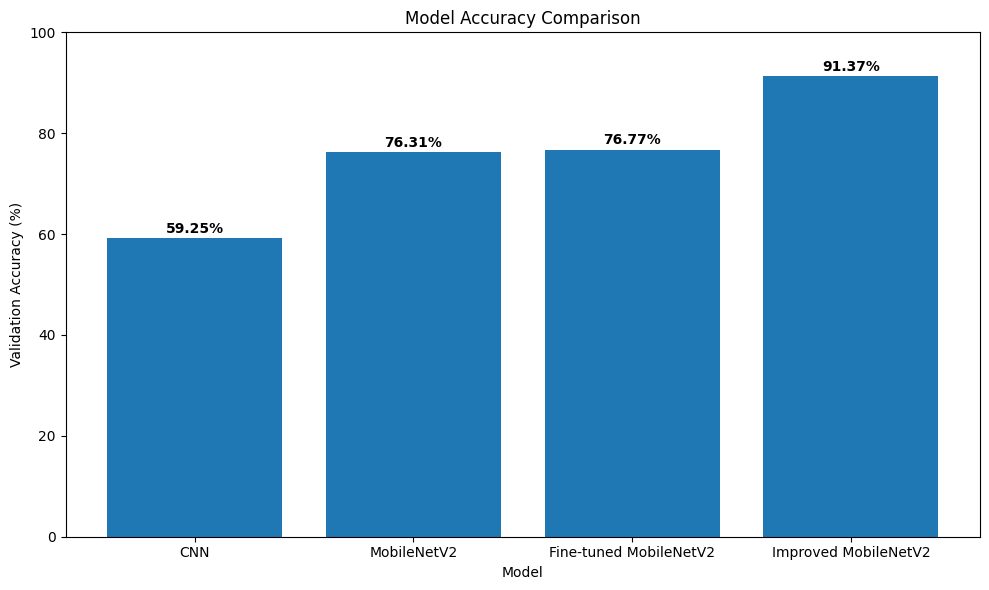

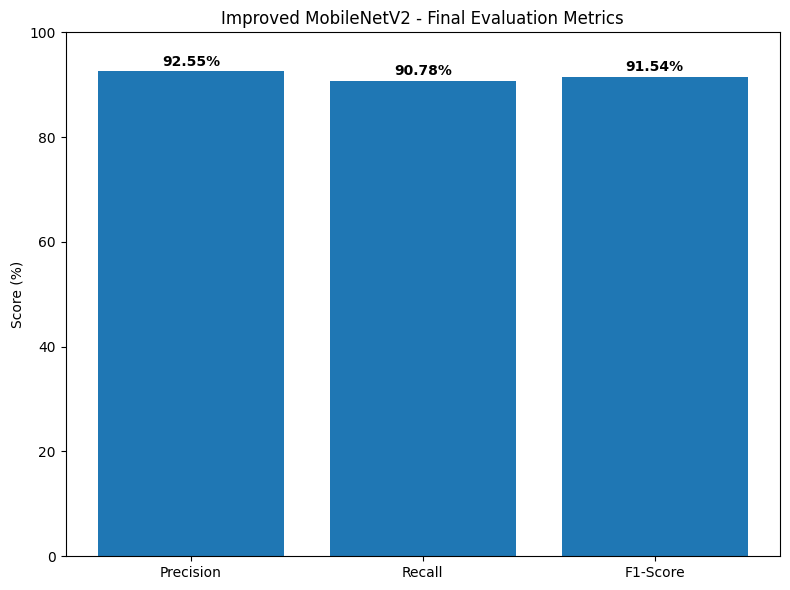

✅ GRAPHS SAVED SUCCESSFULLY

📊 Accuracy Graph:
/content/drive/MyDrive/Fruit Freshness Project/model_accuracy_comparison.png

📊 Final Metrics Graph:
/content/drive/MyDrive/Fruit Freshness Project/final_model_metrics.png

📄 Metrics CSV:
/content/drive/MyDrive/Fruit Freshness Project/final_model_metrics.csv


In [ ]:
# ============================================================
# 🍎 FRUIT FRESHNESS PROJECT
# FINAL PRESENTATION GRAPHS
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import os

OUTPUT_DIR = "/content/drive/MyDrive/Fruit Freshness Project"

# ------------------------------------------------------------
# 1. MODEL ACCURACY COMPARISON
# ------------------------------------------------------------

models = [
    "CNN",
    "MobileNetV2",
    "Fine-tuned MobileNetV2",
    "Improved MobileNetV2"
]

accuracy = [59.25, 76.31, 76.77, 91.37]

plt.figure(figsize=(10, 6))
bars = plt.bar(models, accuracy)

plt.ylabel("Validation Accuracy (%)")
plt.xlabel("Model")
plt.title("Model Accuracy Comparison")
plt.ylim(0, 100)

for bar, value in zip(bars, accuracy):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 1,
        f"{value:.2f}%",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()

accuracy_path = os.path.join(
    OUTPUT_DIR,
    "model_accuracy_comparison.png"
)

plt.savefig(accuracy_path, dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 2. FINAL MODEL METRICS
# ------------------------------------------------------------

metrics = [
    "Precision",
    "Recall",
    "F1-Score"
]

values = [92.55, 90.78, 91.54]

plt.figure(figsize=(8, 6))
bars = plt.bar(metrics, values)

plt.ylabel("Score (%)")
plt.title("Improved MobileNetV2 - Final Evaluation Metrics")
plt.ylim(0, 100)

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 1,
        f"{value:.2f}%",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()

metrics_path = os.path.join(
    OUTPUT_DIR,
    "final_model_metrics.png"
)

plt.savefig(metrics_path, dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 3. SAVE METRICS TABLE
# ------------------------------------------------------------

metrics_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1-Score"
    ],
    "Score (%)": [
        91.37,
        92.55,
        90.78,
        91.54
    ]
})

metrics_csv = os.path.join(
    OUTPUT_DIR,
    "final_model_metrics.csv"
)

metrics_df.to_csv(metrics_csv, index=False)

print("=" * 60)
print("✅ GRAPHS SAVED SUCCESSFULLY")
print("=" * 60)

print("\n📊 Accuracy Graph:")
print(accuracy_path)

print("\n📊 Final Metrics Graph:")
print(metrics_path)

print("\n📄 Metrics CSV:")
print(metrics_csv)

# **PREDICTION DEMO**

📦 Loading final model...
✅ Model loaded successfully!

📤 Upload a fruit image:


Saving APPLE F.png to APPLE F.png


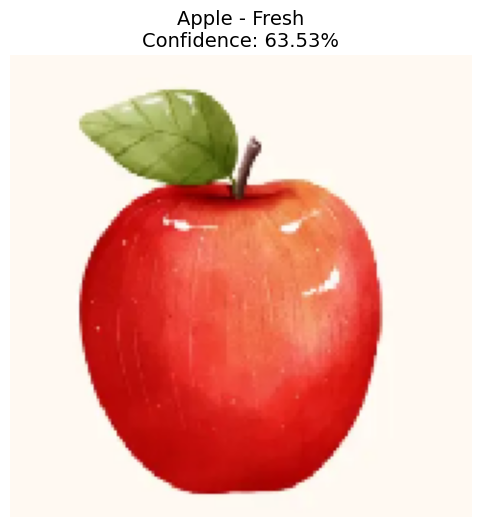

🍎 FINAL PREDICTION RESULT
Fruit       : Apple
Condition   : Fresh
Confidence  : 63.53%
Class       : Apple_Fresh

🔝 Top 5 Predictions:
1. Apple_Fresh               63.53%
2. Apple_Rotten              35.53%
3. Grapes_Fresh              0.93%
4. Orange_Fresh              0.00%
5. Jujube_Fresh              0.00%


In [ ]:
# ============================================================
# 🍎 FINAL FRUIT FRESHNESS PREDICTION DEMO
# ============================================================

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# ------------------------------------------------------------
# MODEL PATH
# ------------------------------------------------------------

MODEL_PATH = "/content/drive/MyDrive/Fruit Freshness Project/mobilenetv2_improved_best.keras"

# ------------------------------------------------------------
# CLASS NAMES
# ------------------------------------------------------------

class_names = [
    "Apple_Fresh", "Apple_Rotten",
    "Banana_Fresh", "Banana_Rotten",
    "Grape_Fresh", "Grape_Rotten",
    "Grapes_Fresh", "Grapes_Rotten",
    "Guava_Fresh", "Guava_Rotten",
    "Jujube_Fresh", "Jujube_Rotten",
    "Kaki_Fresh", "Kaki_Rotten",
    "Mango_Fresh", "Mango_Rotten",
    "Orange_Fresh", "Orange_Rotten",
    "Papaya_Fresh", "Papaya_Rotten",
    "Peach_Fresh", "Peach_Rotten",
    "Pear_Fresh", "Pear_Rotten",
    "Pomegranate_Fresh", "Pomegranate_Rotten",
    "Strawberry_Fresh", "Strawberry_Rotten",
    "Watermelon_Fresh", "Watermelon_Rotten"
]

# ------------------------------------------------------------
# LOAD MODEL
# ------------------------------------------------------------

print("📦 Loading final model...")

model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)

print("✅ Model loaded successfully!\n")

# ------------------------------------------------------------
# UPLOAD IMAGE
# ------------------------------------------------------------

print("📤 Upload a fruit image:")

uploaded = files.upload()

file_name = list(uploaded.keys())[0]

# ------------------------------------------------------------
# LOAD + RESIZE IMAGE
# ------------------------------------------------------------

image = tf.keras.utils.load_img(
    file_name,
    target_size=(160, 160)
)

image_array = tf.keras.utils.img_to_array(image)
image_batch = np.expand_dims(image_array, axis=0)

# ------------------------------------------------------------
# PREDICTION
# ------------------------------------------------------------

predictions = model.predict(
    image_batch,
    verbose=0
)[0]

predicted_index = np.argmax(predictions)

predicted_class = class_names[predicted_index]
confidence = predictions[predicted_index] * 100

# ------------------------------------------------------------
# FRUIT + CONDITION
# ------------------------------------------------------------

if predicted_class.endswith("_Fresh"):
    fruit = predicted_class.replace("_Fresh", "")
    condition = "Fresh"

elif predicted_class.endswith("_Rotten"):
    fruit = predicted_class.replace("_Rotten", "")
    condition = "Rotten"

# ------------------------------------------------------------
# DISPLAY IMAGE
# ------------------------------------------------------------

plt.figure(figsize=(6, 6))

plt.imshow(image)
plt.axis("off")

plt.title(
    f"{fruit} - {condition}\nConfidence: {confidence:.2f}%",
    fontsize=14
)

plt.show()

# ------------------------------------------------------------
# FINAL RESULT
# ------------------------------------------------------------

print("=" * 50)
print("🍎 FINAL PREDICTION RESULT")
print("=" * 50)

print(f"Fruit       : {fruit}")
print(f"Condition   : {condition}")
print(f"Confidence  : {confidence:.2f}%")
print(f"Class       : {predicted_class}")

# ------------------------------------------------------------
# TOP 5 PREDICTIONS
# ------------------------------------------------------------

top5_indices = np.argsort(predictions)[-5:][::-1]

print("\n🔝 Top 5 Predictions:")

for rank, index in enumerate(top5_indices, start=1):
    print(
        f"{rank}. {class_names[index]:25s} "
        f"{predictions[index] * 100:.2f}%"
    )